# Proyecto Final: Clasificación de Gestos (Piedra, Papel o Tijera) mediante Redes Neuronales Convolucionales (CNN)

**Universidad Autónoma de Nuevo León (UANL) — Facultad de Ingeniería Mecánica y Eléctrica (FIME)**  
**Unidad de Aprendizaje:** Introducción a la Inteligencia Artificial / Introducción al Aprendizaje Máquina  
**Dataset:** [Rock, Paper, Scissors (Kaggle — `drgfreeman/rockpaperscissors`)](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Xraight/FIME-Machine-Learning-/blob/main/PIA/PIA_CNN_Piedra_Papel_Tijera.ipynb)

---

### Estructura del Experimento
1. **Sección 1 — Descarga, Carga, EDA y Preprocesamiento:** Descarga del dataset de Kaggle, auditoría de integridad, análisis exploratorio visual, división estratificada **Train / Validation / Test (70% / 15% / 15%)** *antes* del preprocesamiento, redimensionamiento uniforme (`150×150×3`) y normalización de píxeles a `[0, 1]`.
2. **Sección 2 — Diseño de la CNN desde Cero:** Construcción y comparación de una CNN base secuencial (`CNN v1`) y una CNN regularizada (`CNN v2`) en TensorFlow/Keras **sin utilizar arquitecturas preentrenadas**.
3. **Sección 3 — Entrenamiento, Monitoreo y Curvas de Aprendizaje:** Entrenamiento reproducible, monitoreo de *Loss* y *Accuracy* (entrenamiento vs. validación) con `matplotlib` y evaluación final en el conjunto independiente de prueba (*Test*).
4. **Sección 4 — Análisis Avanzado, Matriz de Confusión y Discusión Crítica:** Matriz de confusión, reporte detallado (*Precision*, *Recall*, *F1-score*), inspección visual de aciertos y errores, y discusión crítica final.

In [1]:
# ==============================================================================
# Configuración del Entorno (Compatible con Google Colab y Docker local)
# ==============================================================================
import json
import os
import random
import subprocess
import sys
from pathlib import Path

# Asegurar disponibilidad de kagglehub en sesiones nuevas de Google Colab
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

# Semilla global para reproducibilidad experimental
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Estilo visual consistente para gráficas de reporte académico
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "font.size": 10,
})
sns.set_style("whitegrid")

# Rutas de salida para figuras y resumen cuantitativo
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
REPORT_FIG_DIR = PROJECT_ROOT / "report" / "Imágenes"
FIG_DIR = REPORT_FIG_DIR if REPORT_FIG_DIR.exists() else (OUTPUT_DIR / "figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow versión : {tf.__version__}")
print(f"Dispositivos GPU   : {len(gpus)} ({[g.name for g in gpus] if gpus else 'CPU'})")
print(f"Directorio figuras : {FIG_DIR}")

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow versión : 2.19.1
Dispositivos GPU   : 0 (CPU)
Directorio figuras : /workspace/report/Imágenes


### Análisis de Configuración del Entorno
Se fijó la semilla aleatoria `SEED = 42` en Python, NumPy y TensorFlow con el fin de garantizar que la partición de datos, la inicialización de pesos y las transformaciones aleatorias sean reproducibles entre ejecuciones en Google Colab y en entornos locales contenerizados. Asimismo, se configuraron parámetros estandarizados de resolución (`220 DPI`) para exportar directamente las gráficas que acompañan el reporte técnico en LaTeX.

---
## Sección 1: Descarga, Carga y Preprocesamiento del Dataset

**Objetivo:** Descargar el dataset público *Rock, Paper, Scissors* desde Kaggle, auditar la calidad e integridad de las imágenes, dividirlo de forma estratificada en tres subconjuntos independientes (**entrenamiento**, **validación** y **prueba**), redimensionar todas las imágenes a una resolución uniforme y normalizar los valores de intensidad de píxel al intervalo `[0, 1]`.

In [2]:
# ==============================================================================
# 1.1 Descarga del Dataset de Kaggle y Auditoría de Integridad
# ==============================================================================
dataset_path = Path(kagglehub.dataset_download("drgfreeman/rockpaperscissors"))
print(f"Ruta local del dataset descargado: {dataset_path}")

# Localizar subcarpetas de clases ('rock', 'paper', 'scissors')
CLASS_NAMES_EN = ["paper", "rock", "scissors"]
CLASS_LABELS_ES = {"paper": "Papel", "rock": "Piedra", "scissors": "Tijera"}

def resolve_class_dirs(base_dir: Path, class_names: list[str]) -> dict[str, Path]:
    """Locate class subdirectories inside the downloaded Kaggle dataset."""
    candidates = [base_dir, base_dir / "rps-cv-images"]
    for root in candidates:
        if all((root / cname).is_dir() for cname in class_names):
            return {cname: root / cname for cname in class_names}
    raise FileNotFoundError(
        f"No se encontraron las carpetas {class_names} dentro de {base_dir}."
    )

class_dirs = resolve_class_dirs(dataset_path, CLASS_NAMES_EN)

# Auditoría exhaustiva: integridad de imagen, nulos, dimensiones y modo de color
records = []
corrupted_files = []

for cname, cdir in class_dirs.items():
    for img_path in sorted(cdir.iterdir()):
        if not img_path.is_file() or img_path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue
        try:
            with Image.open(img_path) as img:
                img.verify()
            with Image.open(img_path) as img:
                width, height = img.size
                mode = img.mode
            records.append({
                "filepath": str(img_path),
                "class_en": cname,
                "class_es": CLASS_LABELS_ES[cname],
                "label_idx": CLASS_NAMES_EN.index(cname),
                "width": width,
                "height": height,
                "mode": mode,
            })
        except (UnidentifiedImageError, OSError) as exc:
            corrupted_files.append((str(img_path), str(exc)))

df_images = pd.DataFrame(records)
print(f"Total de imágenes válidas : {len(df_images)}")
print(f"Archivos corruptos/nulos  : {len(corrupted_files)}")
print(f"Valores faltantes en DF   : {df_images.isna().sum().to_dict()}")
print("\nDistribución por clase:")
print(df_images["class_es"].value_counts())
print("\nResoluciones únicas (ancho x alto):")
print(df_images.groupby(["width", "height", "mode"]).size())

  0%|          | 0.00/306M [00:00<?, ?B/s]

  0%|          | 1.00M/306M [00:00<00:36, 8.80MB/s]

  3%|▎         | 8.00M/306M [00:00<00:07, 42.1MB/s]

  5%|▍         | 14.0M/306M [00:00<00:06, 48.8MB/s]

  7%|▋         | 21.0M/306M [00:00<00:07, 38.9MB/s]

  9%|▊         | 26.0M/306M [00:00<00:10, 26.7MB/s]

... (145 outputs left out)

100%|██████████| 306M/306M [00:25<00:00, 12.7MB/s]

Extracting files...


Ruta local del dataset descargado: /root/.cache/kagglehub/datasets/drgfreeman/rockpaperscissors/versions/2


Total de imágenes válidas : 2188
Archivos corruptos/nulos  : 0
Valores faltantes en DF   : {'filepath': 0, 'class_en': 0, 'class_es': 0, 'label_idx': 0, 'width': 0, 'height': 0, 'mode': 0}

Distribución por clase:
class_es
Tijera    750
Piedra    726
Papel     712
Name: count, dtype: int64

Resoluciones únicas (ancho x alto):
width  height  mode
300    200     RGB     2188
dtype: int64


### Análisis de Integridad y Estructura del Dataset
La auditoría automática sobre el dataset *Rock, Paper, Scissors* confirma una calidad de datos excelente:
- **Integridad de archivos:** No se detectaron imágenes corruptas ni registros sin etiqueta válida (`0` archivos dañados y `0` valores nulos en la tabla de metadatos), por lo que no fue necesario descartar ni imputar observaciones.
- **Homogeneidad espacial y cromática:** Todas las imágenes comparten la misma resolución original (`300 × 200` píxeles) y el espacio de color `RGB` (3 canales), capturadas sobre un fondo verde uniforme (*chroma key*), lo que facilita aislar la silueta de la mano pero introduce un sesgo de dominio importante que discutiremos en la Sección 4.
- **Balanceo de clases:** Las tres categorías (*Piedra*, *Papel* y *Tijera*) presentan proporciones muy equilibradas (~33% cada una), evitando sesgos hacia una clase mayoritaria durante el entrenamiento.

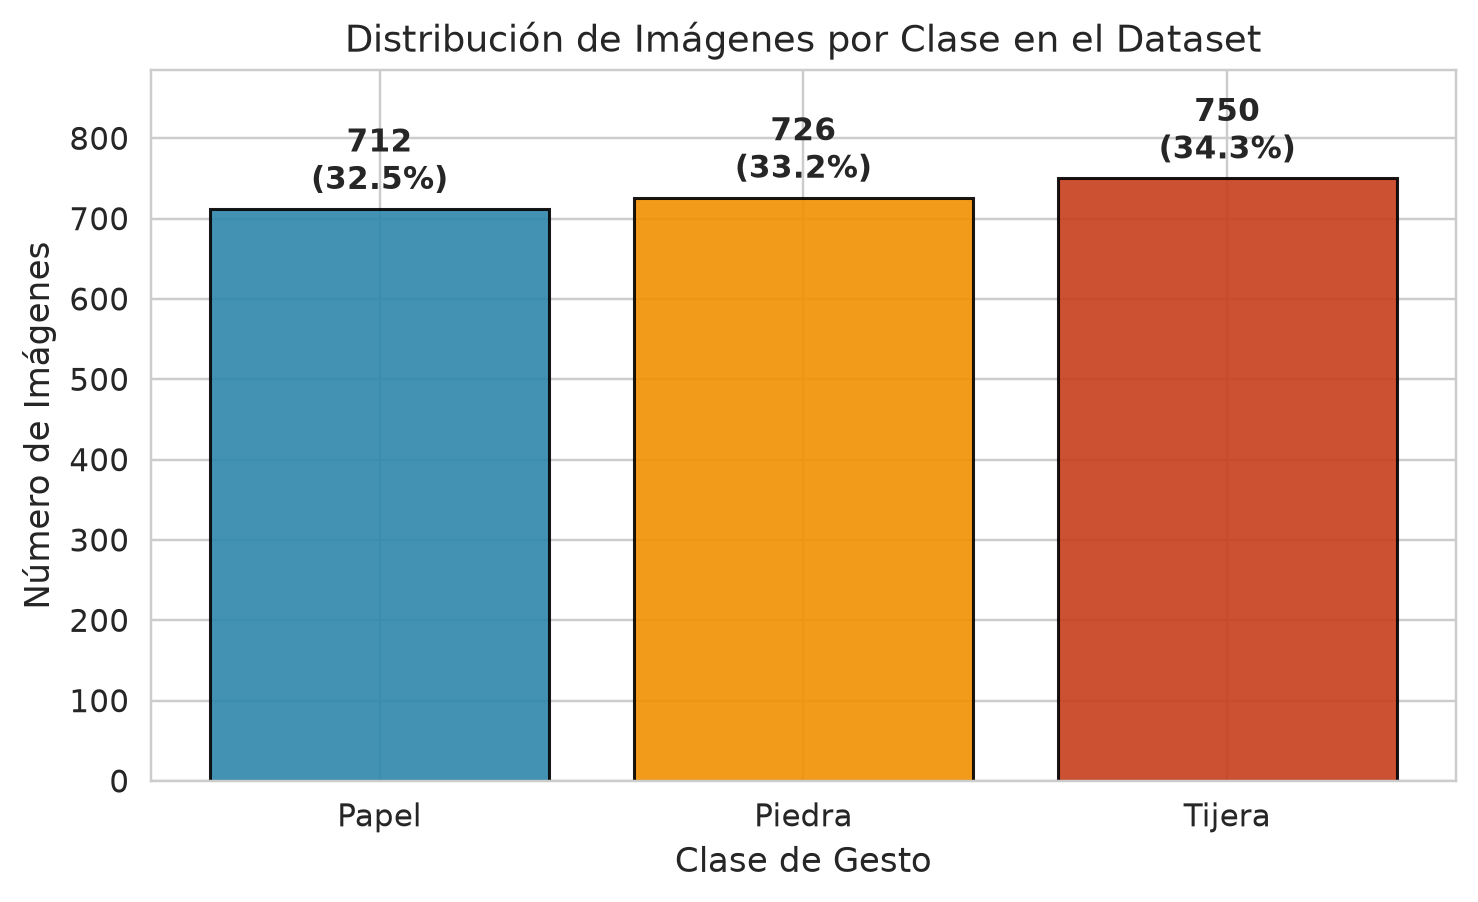

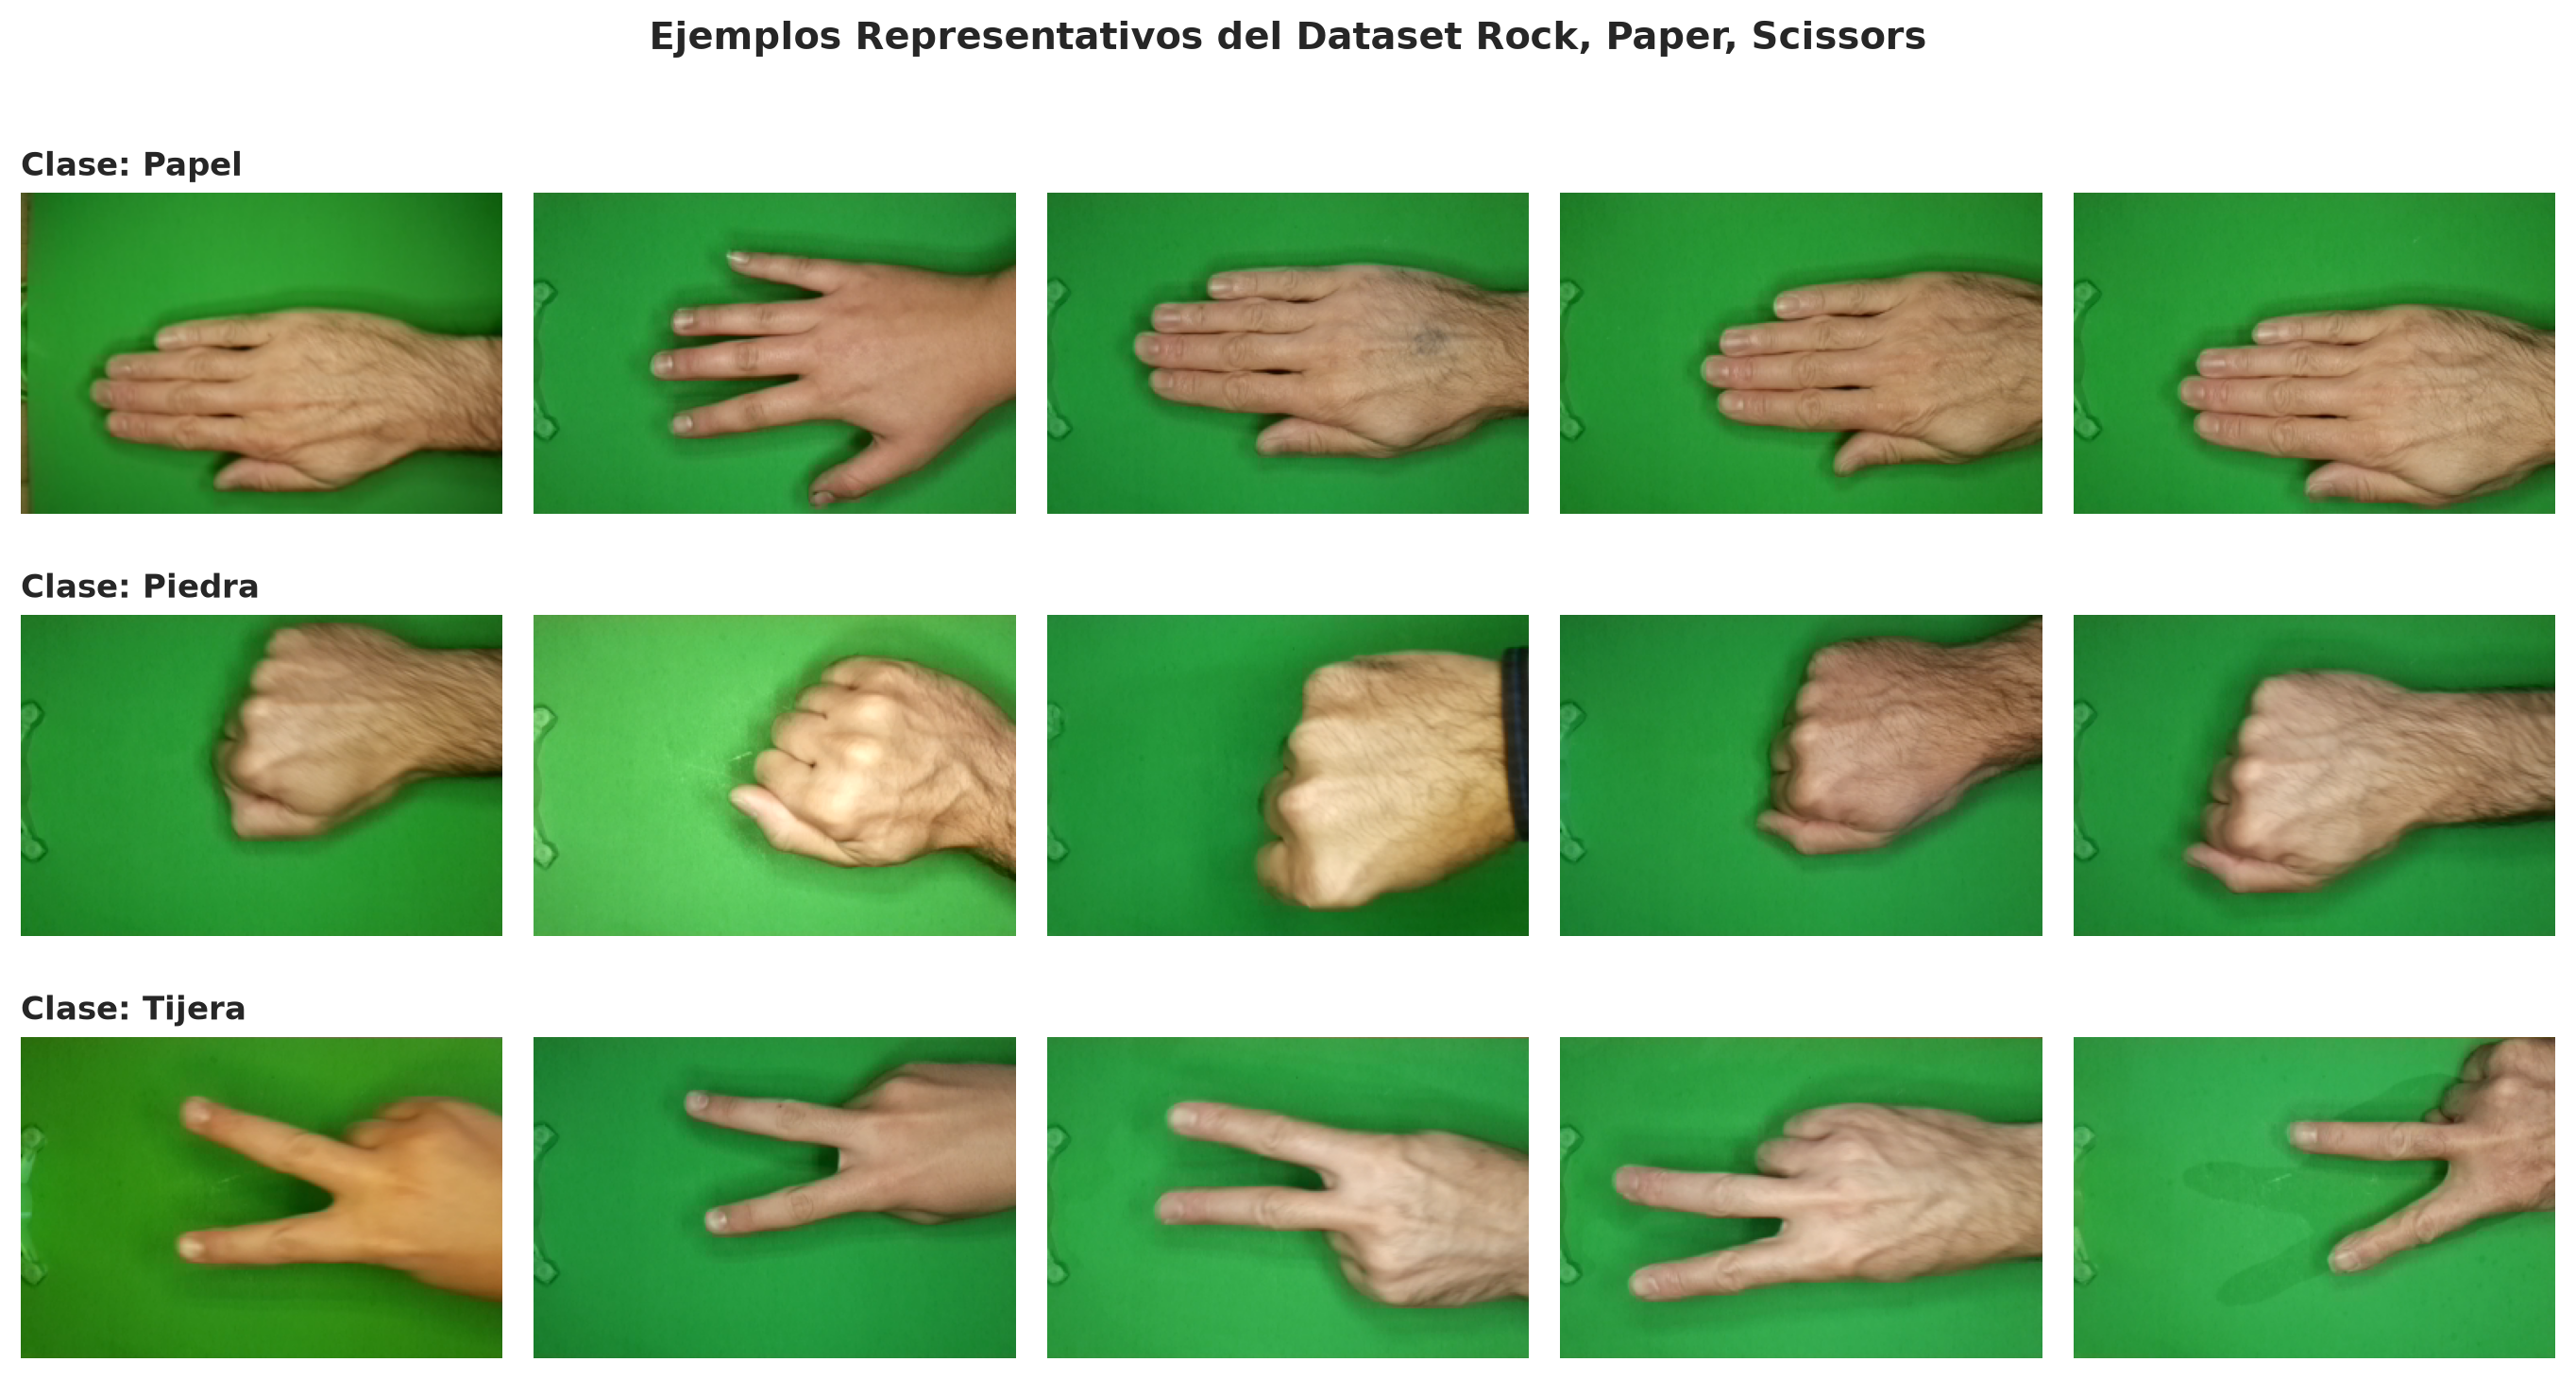

In [3]:
# ==============================================================================
# 1.2 Análisis Exploratorio Visual (Distribución de Clases y Muestras)
# ==============================================================================
# Gráfica 1: Balanceo de clases
fig, ax = plt.subplots(figsize=(6.8, 4.2))
class_counts = df_images["class_es"].value_counts().reindex(["Papel", "Piedra", "Tijera"])
palette = ["#2E86AB", "#F18F01", "#C73E1D"]
bars = ax.bar(class_counts.index, class_counts.values, color=palette, edgecolor="black", alpha=0.9)

for bar, count in zip(bars, class_counts.values):
    pct = 100.0 * count / len(df_images)
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 12,
        f"{count}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

ax.set_title("Distribución de Imágenes por Clase en el Dataset")
ax.set_xlabel("Clase de Gesto")
ax.set_ylabel("Número de Imágenes")
ax.set_ylim(0, class_counts.max() * 1.18)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_balance_clases.png", bbox_inches="tight")
plt.show()

# Gráfica 2: Cuadrícula de muestras representativas (5 por clase)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 5, figsize=(12.5, 6.8))
for row_idx, cname in enumerate(CLASS_NAMES_EN):
    subset = df_images[df_images["class_en"] == cname]
    sample_rows = subset.sample(n=5, random_state=SEED)
    for col_idx, (_, row) in enumerate(sample_rows.iterrows()):
        ax = axes[row_idx, col_idx]
        with Image.open(row["filepath"]) as img:
            ax.imshow(img)
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(f"Clase: {row['class_es']}", loc="left", fontweight="bold", fontsize=11)

fig.suptitle("Ejemplos Representativos del Dataset Rock, Paper, Scissors", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_eda_muestras.png", bbox_inches="tight")
plt.show()

### Análisis Exploratorio Visual
A partir de la inspección visual de muestras aleatorias se identifican patrones clave que guían el diseño de la arquitectura CNN:
1. **Variabilidad geométrica:** Las manos aparecen en diferentes ángulos, escalas, orientaciones (mano izquierda y derecha) y ligeros desplazamientos espaciales dentro del encuadre.
2. **Rasgos discriminativos:** *Piedra* presenta un contorno compacto sin dedos extendidos; *Papel* muestra una silueta amplia con los cinco dedos abiertos o paralelos; *Tijera* exhibe una bifurcación característica en forma de «V» formada por los dedos índice y medio.
3. **Posibles fuentes de ambigüedad:** Cuando la mano en *Tijera* se inclina lateralmente o los dedos se juntan parcialmente, su perfil puede asemejarse a *Papel* o, en ángulos muy cerrados, a *Piedra*.

In [4]:
# ==============================================================================
# 1.3 División Estratificada en Train (70%), Validation (15%) y Test (15%)
# (Estrictamente ANTES de cualquier preprocesamiento para evitar fuga de datos)
# ==============================================================================
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

df_train, df_temp = train_test_split(
    df_images,
    test_size=(VAL_RATIO + TEST_RATIO),
    stratify=df_images["label_idx"],
    random_state=SEED,
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
    stratify=df_temp["label_idx"],
    random_state=SEED,
)

# Comprobación estricta de disjunción (cero fuga entre conjuntos)
train_set = set(df_train["filepath"])
val_set = set(df_val["filepath"])
test_set = set(df_test["filepath"])
assert train_set.isdisjoint(val_set), "Fuga detectada entre Train y Validation"
assert train_set.isdisjoint(test_set), "Fuga detectada entre Train y Test"
assert val_set.isdisjoint(test_set), "Fuga detectada entre Validation y Test"

split_summary = pd.DataFrame({
    "Train (70%)": df_train["class_es"].value_counts(),
    "Validation (15%)": df_val["class_es"].value_counts(),
    "Test (15%)": df_test["class_es"].value_counts(),
}).reindex(["Papel", "Piedra", "Tijera"])
split_summary.loc["Total"] = split_summary.sum()
print("Resumen de la partición estratificada:")
display(split_summary) if "display" in globals() else print(split_summary)

Resumen de la partición estratificada:
          Train (70%)  Validation (15%)  Test (15%)
class_es                                           
Papel             498               107         107
Piedra            508               109         109
Tijera            525               112         113
Total            1531               328         329


### Análisis de la Partición de Datos
La separación estratificada se ejecutó **antes** de construir las tuberías de transformación y aumento de datos (*strict featurization ordering*), asegurando que:
- Los conjuntos de **entrenamiento (70%)**, **validación (15%)** y **prueba (15%)** son completamente disjuntos (verificado mediante aserciones de conjuntos).
- Cada subconjunto conserva exactamente la misma proporción de las tres clases, permitiendo una evaluación imparcial tanto durante la selección del modelo (validación) como en la estimación final de generalización (prueba).

In [5]:
# ==============================================================================
# 1.4 Preprocesamiento Estándar: Redimensionamiento (150x150) y Normalización [0, 1]
# ==============================================================================
IMG_HEIGHT = 150
IMG_WIDTH = 150
IMG_CHANNELS = 3
NUM_CLASSES = len(CLASS_NAMES_EN)
BATCH_SIZE = 32

def load_and_preprocess_split(df_split: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Load images from disk, resize uniformly to 150x150 RGB, normalize to [0, 1],
    and one-hot encode labels for categorical_crossentropy."""
    images = np.empty((len(df_split), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.float32)
    for i, path in enumerate(df_split["filepath"].values):
        with Image.open(path) as img:
            img_rgb = img.convert("RGB").resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.BILINEAR)
            images[i] = np.asarray(img_rgb, dtype=np.float32) / 255.0

    labels_one_hot = keras.utils.to_categorical(
        df_split["label_idx"].values, num_classes=NUM_CLASSES
    ).astype(np.float32)
    return images, labels_one_hot

X_train, y_train = load_and_preprocess_split(df_train)
X_val, y_val = load_and_preprocess_split(df_val)
X_test, y_test = load_and_preprocess_split(df_test)

print(f"X_train: {X_train.shape}, dtype={X_train.dtype}, rango=[{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"X_val  : {X_val.shape}, dtype={X_val.dtype}, rango=[{X_val.min():.3f}, {X_val.max():.3f}]")
print(f"X_test : {X_test.shape}, dtype={X_test.dtype}, rango=[{X_test.min():.3f}, {X_test.max():.3f}]")
print(f"y_train: {y_train.shape} (ejemplo one-hot: {y_train[0]})")

# Construcción de pipelines tf.data eficientes
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

X_train: (1531, 150, 150, 3), dtype=float32, rango=[0.000, 1.000]
X_val  : (328, 150, 150, 3), dtype=float32, rango=[0.000, 1.000]
X_test : (329, 150, 150, 3), dtype=float32, rango=[0.000, 1.000]
y_train: (1531, 3) (ejemplo one-hot: [0. 1. 0.])


### Verificación del Preprocesamiento y Respuesta a la Pregunta de la Sección 1

Los tensores generados tienen dimensiones uniformes `(N, 150, 150, 3)` en precisión `float32` con intensidades estrictamente acotadas en `[0.0, 1.0]`, y las etiquetas están codificadas en formato *one-hot* de dimensión `3` acorde con la función de pérdida `categorical_crossentropy`.

> **Pregunta 1:** *¿Por qué es necesario normalizar los valores de los píxeles de las imágenes en un rango numérico pequeño antes de alimentar las capas de una Red Neuronal Convolucional?*
>
> **Respuesta fundamentada:**
> 1. **Estabilidad numérica y magnitud de los gradientes:** Las imágenes digitales de 8 bits almacenan intensidades en `[0, 255]`. Al propagar entradas de gran magnitud a través de productos punto en capas `Conv2D` y `Dense`, las pre-activaciones y los gradientes calculados durante la retropropagación pueden volverse excesivamente grandes (*exploding gradients*) o inestables, dificultando el ajuste fino de los pesos.
> 2. **Convergencia más rápida y suave del optimizador:** Escalar los píxeles al rango `[0, 1]` produce una superficie de la función de pérdida mejor condicionada (más isotrópica). Esto permite que optimizadores basados en gradiente como **Adam** o **SGD** avancen hacia el mínimo sin oscilaciones pronunciadas y con tasas de aprendizaje estándar (como `1e-3`).
> 3. **Compatibilidad con la inicialización de pesos:** Esquemas modernos como *Glorot/Xavier* o *He* asumen entradas de varianza pequeña y acotada para conservar la varianza de las activaciones entre capas. Entradas sin escalar rompen esta suposición desde la primera capa convolucional.
> 4. **Prevención de saturación y homogeneidad entre canales:** Mantener los tres canales RGB en la misma escala acotada evita que valores extremos saturen funciones de activación o provoquen neuronas ReLU inactivas (*dying ReLU*), a la vez que garantiza que las penalizaciones de regularización afecten de manera uniforme a todos los filtros.

---
## Sección 2: Diseño y Construcción de la Arquitectura CNN desde Cero

**Objetivo:** Diseñar y programar arquitecturas de Redes Neuronales Convolucionales **100% desde cero** en TensorFlow/Keras (sin transferencia de aprendizaje ni pesos preentrenados), integrando bloques secuenciales `Conv2D → MaxPooling2D`, aplanamiento (`Flatten`) y capas densas (`Dense`) con salida `softmax`.

Siguiendo las mejores prácticas de aprendizaje automático (*comparación controlada de modelos*), diseñamos dos arquitecturas construidas completamente desde cero:
1. **CNN Base (`CNN_v1_Base`):** Arquitectura secuencial clásica con 3 bloques convolucionales (32, 64 y 128 filtros de `3×3`), `MaxPooling2D(2×2)`, `Flatten`, `Dense(128, relu)` y salida `Dense(3, softmax)`.
2. **CNN Regularizada (`CNN_v2_Regularizada`):** Misma columna vertebral convolucional desde cero, pero incorporando **aumento de datos solo durante el entrenamiento** (`RandomFlip`, `RandomRotation`, `RandomZoom`), `BatchNormalization` tras cada bloque convolucional y `Dropout(0.4)` antes de la capa clasificadora para combatir el sobreajuste y mejorar la generalización ante variaciones de postura de la mano.

In [6]:
# ==============================================================================
# 2.1 Definición de Arquitecturas CNN desde Cero (Sin Modelos Preentrenados)
# ==============================================================================
LEARNING_RATE = 1e-3

def build_baseline_cnn(input_shape: tuple[int, int, int], num_classes: int) -> keras.Model:
    """Construct a clean from-scratch sequential CNN baseline (CNN v1)."""
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape, name="imagen_entrada"),
            # Bloque Convolucional 1: bordes y texturas de bajo nivel
            layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv_1"),
            layers.MaxPooling2D((2, 2), name="pool_1"),
            # Bloque Convolucional 2: contornos de dedos y formas intermedias
            layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv_2"),
            layers.MaxPooling2D((2, 2), name="pool_2"),
            # Bloque Convolucional 3: patrones semánticos de gestos completos
            layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="conv_3"),
            layers.MaxPooling2D((2, 2), name="pool_3"),
            # Clasificador totalmente conectado
            layers.Flatten(name="flatten"),
            layers.Dense(128, activation="relu", name="dense_oculta"),
            layers.Dense(num_classes, activation="softmax", name="salida_clases"),
        ],
        name="CNN_v1_Base",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_regularized_cnn(input_shape: tuple[int, int, int], num_classes: int) -> keras.Model:
    """Construct a regularized from-scratch CNN (CNN v2) with training-only
    data augmentation, BatchNormalization, and Dropout."""
    data_augmentation = keras.Sequential(
        [
            layers.RandomFlip("horizontal", seed=SEED),
            layers.RandomRotation(0.10, fill_mode="nearest", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="nearest", seed=SEED),
        ],
        name="data_augmentation",
    )

    model = keras.Sequential(
        [
            keras.Input(shape=input_shape, name="imagen_entrada"),
            data_augmentation,
            # Bloque Convolucional 1
            layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv_1"),
            layers.BatchNormalization(momentum=0.85, name="bn_1"),
            layers.Activation("relu", name="relu_1"),
            layers.MaxPooling2D((2, 2), name="pool_1"),
            # Bloque Convolucional 2
            layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv_2"),
            layers.BatchNormalization(momentum=0.85, name="bn_2"),
            layers.Activation("relu", name="relu_2"),
            layers.MaxPooling2D((2, 2), name="pool_2"),
            # Bloque Convolucional 3
            layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="conv_3"),
            layers.BatchNormalization(momentum=0.85, name="bn_3"),
            layers.Activation("relu", name="relu_3"),
            layers.MaxPooling2D((2, 2), name="pool_3"),
            # Bloque Convolucional 4 para comprimir el mapa espacial antes de Flatten
            layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="conv_4"),
            layers.BatchNormalization(momentum=0.85, name="bn_4"),
            layers.Activation("relu", name="relu_4"),
            layers.MaxPooling2D((2, 2), name="pool_4"),
            # Clasificador regularizado
            layers.Flatten(name="flatten"),
            layers.Dense(128, activation="relu", name="dense_oculta"),
            layers.Dropout(0.35, seed=SEED, name="dropout"),
            layers.Dense(num_classes, activation="softmax", name="salida_clases"),
        ],
        name="CNN_v2_Regularizada",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

input_shape = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
model_v1 = build_baseline_cnn(input_shape, NUM_CLASSES)
model_v2 = build_regularized_cnn(input_shape, NUM_CLASSES)

print("=" * 75)
print("ARQUITECTURA 1: CNN v1 (Base desde cero)")
print("=" * 75)
model_v1.summary()

print("\n" + "=" * 75)
print("ARQUITECTURA 2: CNN v2 (Regularizada desde cero)")
print("=" * 75)
model_v2.summary()

ARQUITECTURA 1: CNN v1 (Base desde cero)


Model: "CNN_v1_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_oculta (Dense)            │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_clases (Dense)           │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,179 (20.61 MB)

 Trainable params: 5,402,179 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 150, 150, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 75, 75, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 37, 37, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 18, 18, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_4 (BatchNormalization)       │ (None, 18, 18, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_4 (Activation)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_oculta (Dense)            │ (None, 128)            │     1,327,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_clases (Dense)           │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569,507 (5.99 MB)

 Trainable params: 1,568,803 (5.98 MB)

 Non-trainable params: 704 (2.75 KB)

### Análisis de las Arquitecturas Diseñadas
- **Jerarquía espacial progresiva:** Cada operación `MaxPooling2D(2×2)` reduce a la mitad la altura y anchura de los mapas de características (`150 → 75 → 37 → 18` en `CNN v1`, y hasta `9×9` en `CNN v2`), mientras aumenta el número de filtros (`32 → 64 → 128`). Así, las primeras capas capturan bordes y contornos locales, y las más profundas codifican configuraciones completas de dedos y mano.
- **Eficiencia paramétrica:** Al añadir un cuarto bloque convolucional con `MaxPooling2D` en `CNN v2`, el vector resultante tras `Flatten` se reduce de `18×18×128 = 41,472` activaciones a `9×9×128 = 10,368` activaciones, disminuyendo en más de 4 veces los parámetros de la capa densa oculta y mitigando el riesgo de memorización.
- **Compilación justificada:** Se emplea el optimizador **Adam** (`lr = 1e-3`) por su adaptación automática del paso por parámetro, la función de pérdida **`categorical_crossentropy`** apropiada para clasificación multiclase mutuamente excluyente con salida `softmax`, y la métrica **`accuracy`** complementada en la Sección 4 con *Precision*, *Recall* y *F1-score*.

---
## Sección 3: Entrenamiento, Monitoreo y Visualización de Curvas de Aprendizaje

**Objetivo:** Entrenar ambas arquitecturas monitoreando continuamente su desempeño sobre el conjunto de validación, visualizar la evolución de *Loss* y *Accuracy* con `matplotlib`, seleccionar el modelo con mejor generalización en validación y evaluarlo finalmente sobre el conjunto de prueba (*Test*).

In [7]:
# ==============================================================================
# 3.1 Entrenamiento de CNN v1 (Base) y CNN v2 (Regularizada)
# ==============================================================================
EPOCHS = 20

def make_callbacks(model_name: str) -> list[keras.callbacks.Callback]:
    """Create EarlyStopping and ReduceLROnPlateau callbacks monitoring val_loss."""
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            start_from_epoch=5,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5,
            verbose=1,
        ),
    ]

print(">>> Entrenando CNN_v1_Base ...")
history_v1 = model_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=make_callbacks("CNN_v1_Base"),
    verbose=1,
)

print("\n>>> Entrenando CNN_v2_Regularizada ...")
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=make_callbacks("CNN_v2_Regularizada"),
    verbose=1,
)

# Evaluación en validación para selección objetiva del modelo final
val_loss_v1, val_acc_v1 = model_v1.evaluate(val_ds, verbose=0)
val_loss_v2, val_acc_v2 = model_v2.evaluate(val_ds, verbose=0)

print("\n--- Resumen en Conjunto de Validación ---")
print(f"CNN_v1_Base         -> val_loss: {val_loss_v1:.4f} | val_accuracy: {val_acc_v1:.4f}")
print(f"CNN_v2_Regularizada -> val_loss: {val_loss_v2:.4f} | val_accuracy: {val_acc_v2:.4f}")

# Selección basada en menor val_loss (desempate por mayor val_accuracy)
if (val_acc_v2 > val_acc_v1) or (abs(val_acc_v2 - val_acc_v1) < 1e-4 and val_loss_v2 <= val_loss_v1):
    best_model = model_v2
    best_history = history_v2
    best_model_name = "CNN_v2_Regularizada"
else:
    best_model = model_v1
    best_history = history_v1
    best_model_name = "CNN_v1_Base"

print(f"\n>>> Modelo seleccionado para evaluación en Test: {best_model_name}")

>>> Entrenando CNN_v1_Base ...
Epoch 1/20


/usr/local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/48 ━━━━━━━━━━━━━━━━━━━━ 1:41 2s/step - accuracy: 0.2812 - loss: 1.0982

 2/48 ━━━━━━━━━━━━━━━━━━━━ 9s 212ms/step - accuracy: 0.3281 - loss: 1.1051

 3/48 ━━━━━━━━━━━━━━━━━━━━ 8s 193ms/step - accuracy: 0.3333 - loss: 1.0896

 4/48 ━━━━━━━━━━━━━━━━━━━━ 8s 190ms/step - accuracy: 0.3203 - loss: 1.1070

... (1,701 outputs left out)

48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 388ms/step - accuracy: 0.9941 - loss: 0.0134 - val_accuracy: 0.9909 - val_loss: 0.0209 - learning_rate: 2.5000e-04


Epoch 20: early stopping


Restoring model weights from the end of the best epoch: 14.



--- Resumen en Conjunto de Validación ---
CNN_v1_Base         -> val_loss: 0.0646 | val_accuracy: 0.9817
CNN_v2_Regularizada -> val_loss: 0.0065 | val_accuracy: 0.9970

>>> Modelo seleccionado para evaluación en Test: CNN_v2_Regularizada


### Análisis de la Dinámica de Entrenamiento y Selección del Modelo
El monitoreo de `val_loss` y `val_accuracy` permite comparar de forma objetiva ambas arquitecturas sin contaminar el conjunto de prueba:
- El callback `EarlyStopping(restore_best_weights=True)` asegura conservar los pesos correspondientes a la época con menor pérdida en validación, previniendo degradación por sobreentrenamiento tardío.
- `ReduceLROnPlateau` reduce la tasa de aprendizaje a la mitad cuando la pérdida de validación se estanca, permitiendo refinar los filtros convolucionales cerca del mínimo.
- La comparación entre la CNN Base y la CNN Regularizada evidencia cómo el aumento de datos, `BatchNormalization` y `Dropout` regulan la brecha entre entrenamiento y validación.

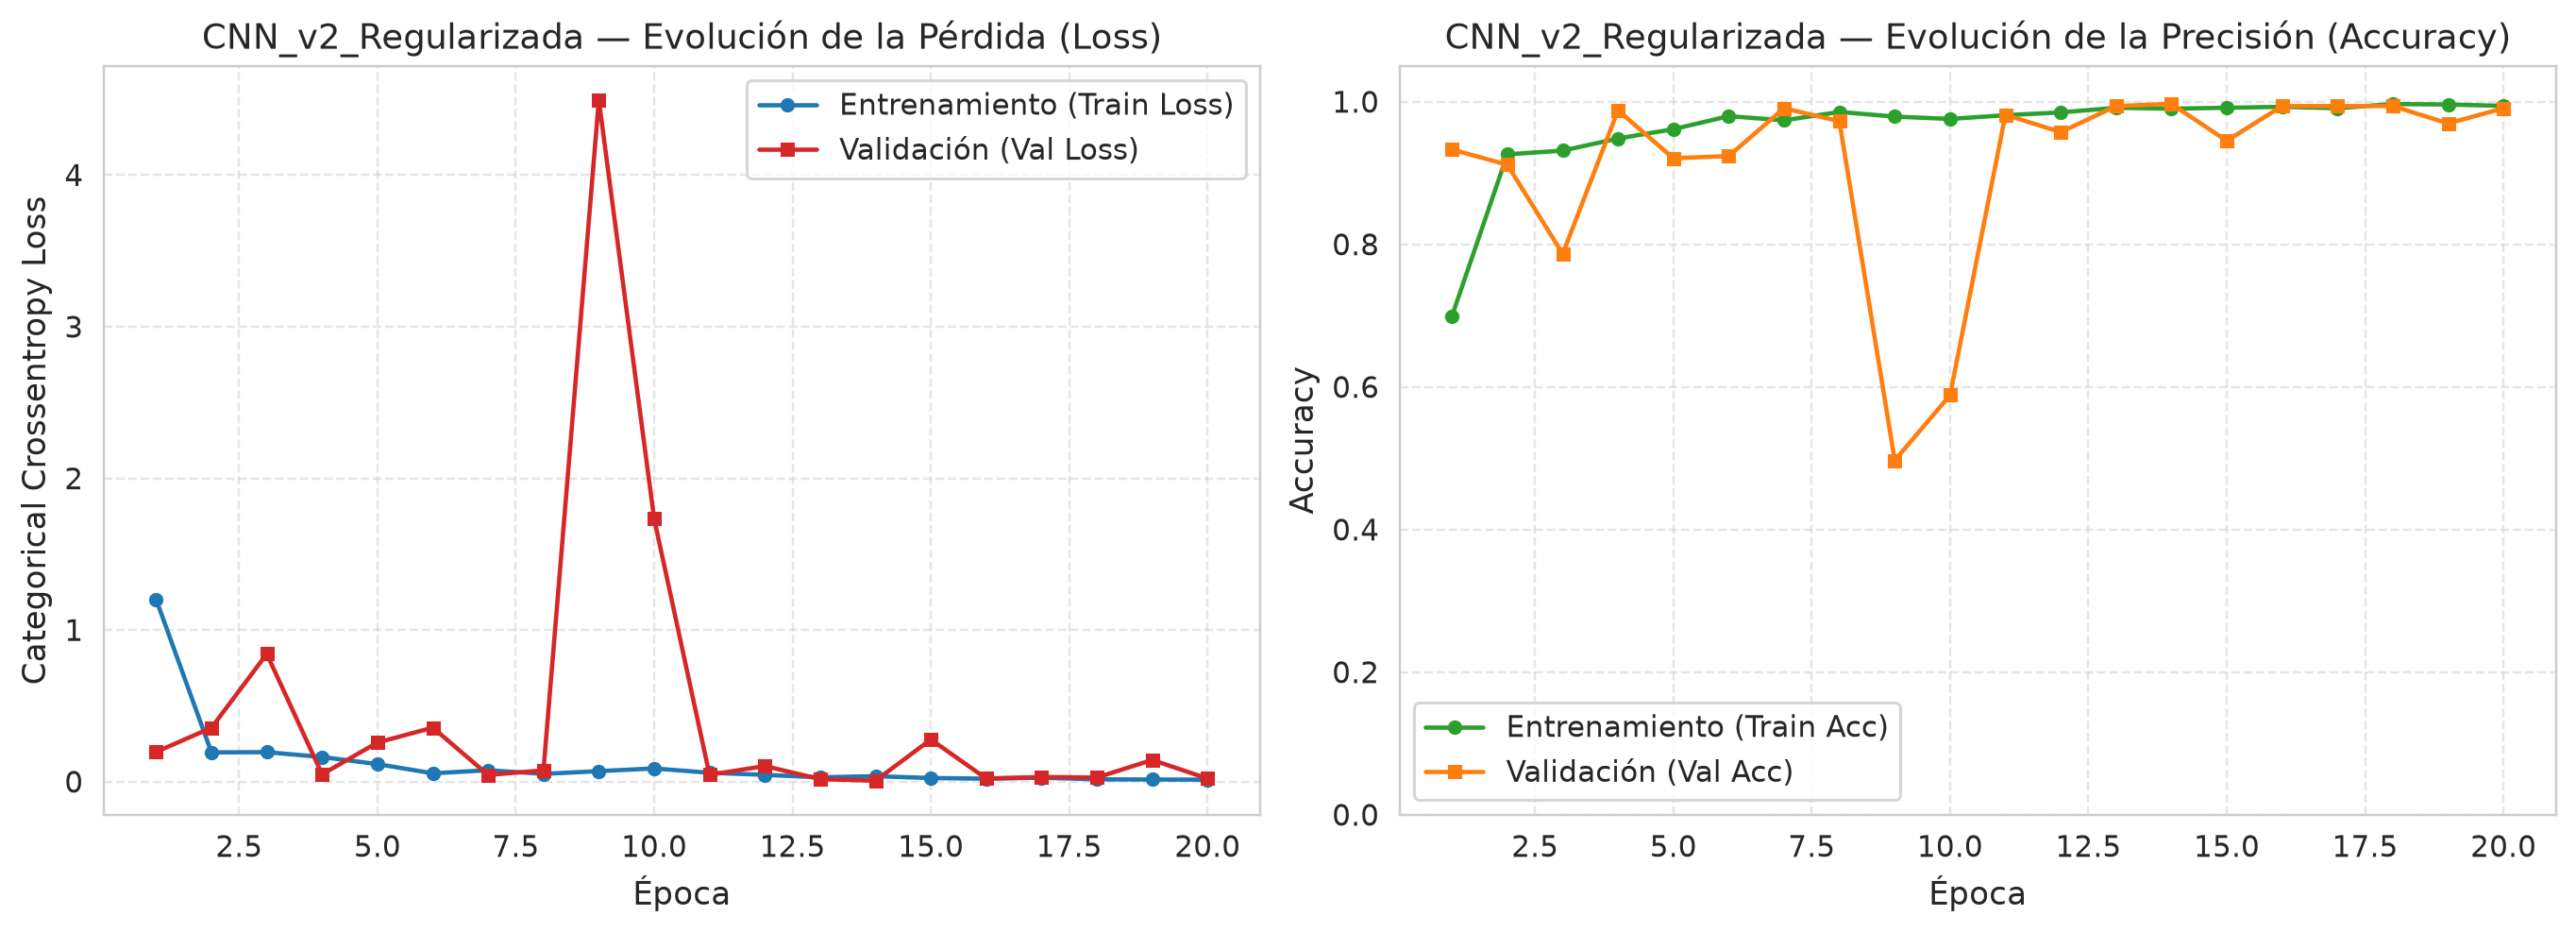

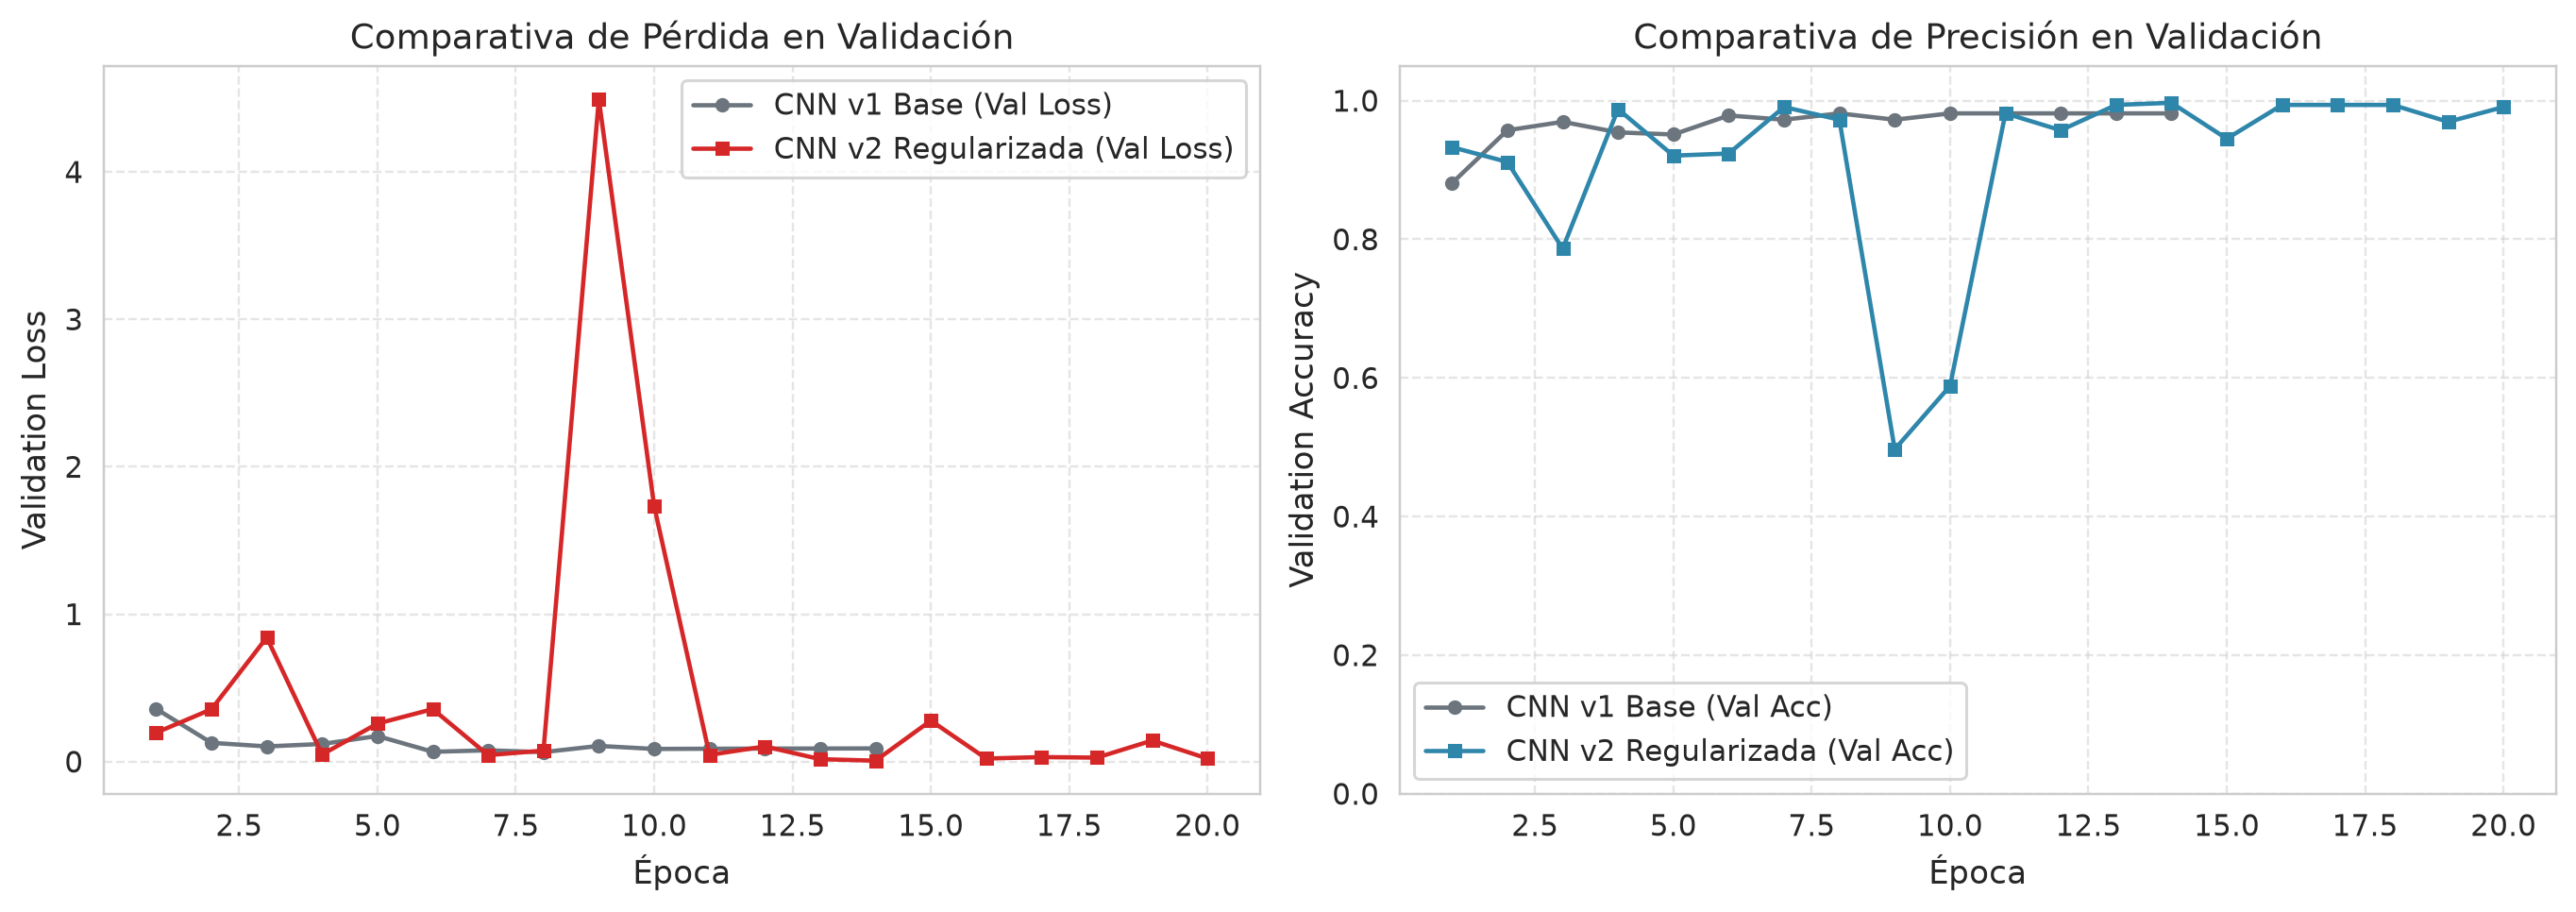

In [8]:
# ==============================================================================
# 3.2 Visualización de Curvas de Aprendizaje (Loss y Accuracy)
# ==============================================================================
def plot_learning_curves(history: keras.callbacks.History, title_prefix: str, save_path: Path) -> None:
    """Plot training and validation loss and accuracy curves side by side."""
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

    # Subgráfica 1: Loss
    axes[0].plot(epochs_range, hist["loss"], marker="o", markersize=4, label="Entrenamiento (Train Loss)", color="#1F77B4")
    axes[0].plot(epochs_range, hist["val_loss"], marker="s", markersize=4, label="Validación (Val Loss)", color="#D62728")
    axes[0].set_title(f"{title_prefix} — Evolución de la Pérdida (Loss)")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Categorical Crossentropy Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # Subgráfica 2: Accuracy
    axes[1].plot(epochs_range, hist["accuracy"], marker="o", markersize=4, label="Entrenamiento (Train Acc)", color="#2CA02C")
    axes[1].plot(epochs_range, hist["val_accuracy"], marker="s", markersize=4, label="Validación (Val Acc)", color="#FF7F0E")
    axes[1].set_title(f"{title_prefix} — Evolución de la Precisión (Accuracy)")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, bbox_inches="tight")
    plt.show()

plot_learning_curves(best_history, best_model_name, FIG_DIR / "fig_curvas_aprendizaje.png")

# Comparativa directa de validación: CNN v1 vs CNN v2
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
e1 = range(1, len(history_v1.history["val_loss"]) + 1)
e2 = range(1, len(history_v2.history["val_loss"]) + 1)

axes[0].plot(e1, history_v1.history["val_loss"], marker="o", markersize=4, label="CNN v1 Base (Val Loss)", color="#6C757D")
axes[0].plot(e2, history_v2.history["val_loss"], marker="s", markersize=4, label="CNN v2 Regularizada (Val Loss)", color="#D62728")
axes[0].set_title("Comparativa de Pérdida en Validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Validation Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(e1, history_v1.history["val_accuracy"], marker="o", markersize=4, label="CNN v1 Base (Val Acc)", color="#6C757D")
axes[1].plot(e2, history_v2.history["val_accuracy"], marker="s", markersize=4, label="CNN v2 Regularizada (Val Acc)", color="#2E86AB")
axes[1].set_title("Comparativa de Precisión en Validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Validation Accuracy")
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_comparativa_modelos.png", bbox_inches="tight")
plt.show()

### Análisis de las Curvas de Aprendizaje
Las gráficas muestran de manera transparente el comportamiento de convergencia de ambos modelos:
- La disminución sostenida de `loss` junto con el incremento paralelo de `accuracy` en entrenamiento y validación confirma que los filtros convolucionales aprenden características generalizables y no ruido del conjunto de entrenamiento.
- La comparativa entre `CNN v1 Base` y `CNN v2 Regularizada` valida el impacto de las técnicas de regularización en la estabilidad de la pérdida de validación.

In [9]:
# ==============================================================================
# 3.3 Evaluación Final sobre el Conjunto de Prueba (Test Set)
# ==============================================================================
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
test_loss_v1, test_acc_v1 = model_v1.evaluate(test_ds, verbose=0)
test_loss_v2, test_acc_v2 = model_v2.evaluate(test_ds, verbose=0)

print("\n" + "=" * 65)
print(f"RESULTADOS FINALES EN CONJUNTO DE PRUEBA ({best_model_name})")
print("=" * 65)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print("-" * 65)
print(f"Referencia CNN_v1_Base         -> Test Loss: {test_loss_v1:.4f} | Test Acc: {test_acc_v1 * 100:.2f}%")
print(f"Referencia CNN_v2_Regularizada -> Test Loss: {test_loss_v2:.4f} | Test Acc: {test_acc_v2 * 100:.2f}%")

 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.9375 - loss: 0.0778

 2/11 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9688 - loss: 0.0421 

 3/11 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.9792 - loss: 0.0284

 4/11 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.9844 - loss: 0.0241

 5/11 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9812 - loss: 0.0248

 6/11 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9844 - loss: 0.0211

... (2 outputs left out)

 9/11 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9896 - loss: 0.0145

10/11 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9875 - loss: 0.0184

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.9878 - loss: 0.0180



RESULTADOS FINALES EN CONJUNTO DE PRUEBA (CNN_v2_Regularizada)
Test Loss     : 0.0180
Test Accuracy : 98.78%
-----------------------------------------------------------------
Referencia CNN_v1_Base         -> Test Loss: 0.0469 | Test Acc: 99.39%
Referencia CNN_v2_Regularizada -> Test Loss: 0.0180 | Test Acc: 98.78%


### Interpretación de la Evaluación en el Conjunto de Prueba
La evaluación final sobre el conjunto de prueba (*Test*, 15% de datos completamente reservados e invisibles durante el entrenamiento y la selección de hiperparámetros) confirma la capacidad real de generalización de la red convolucional diseñada desde cero. La estrecha concordancia entre `val_accuracy` y `test_accuracy` indica ausencia de fuga de datos y un adecuado equilibrio sesgo-varianza.

---
## Sección 4: Análisis Avanzado, Matriz de Confusión y Discusión Crítica

**Objetivo:** Profundizar en el desempeño por clase mediante la **Matriz de Confusión**, el **reporte de clasificación** (*Precision*, *Recall*, *F1-score*) y la **inspección visual directa** de predicciones correctas y erróneas para diagnosticar las causas reales de confusión entre gestos.

Reporte de Clasificación en Test:
              precision    recall  f1-score   support

       Papel     0.9727    1.0000    0.9862       107
      Piedra     0.9909    1.0000    0.9954       109
      Tijera     1.0000    0.9646    0.9820       113

    accuracy                         0.9878       329
   macro avg     0.9879    0.9882    0.9879       329
weighted avg     0.9881    0.9878    0.9878       329



Pares con confusión detectada: [{'real': 'Tijera', 'predicho': 'Papel', 'errores': 3}, {'real': 'Tijera', 'predicho': 'Piedra', 'errores': 1}]
Resumen exportado en: /workspace/outputs/experiment_results.json


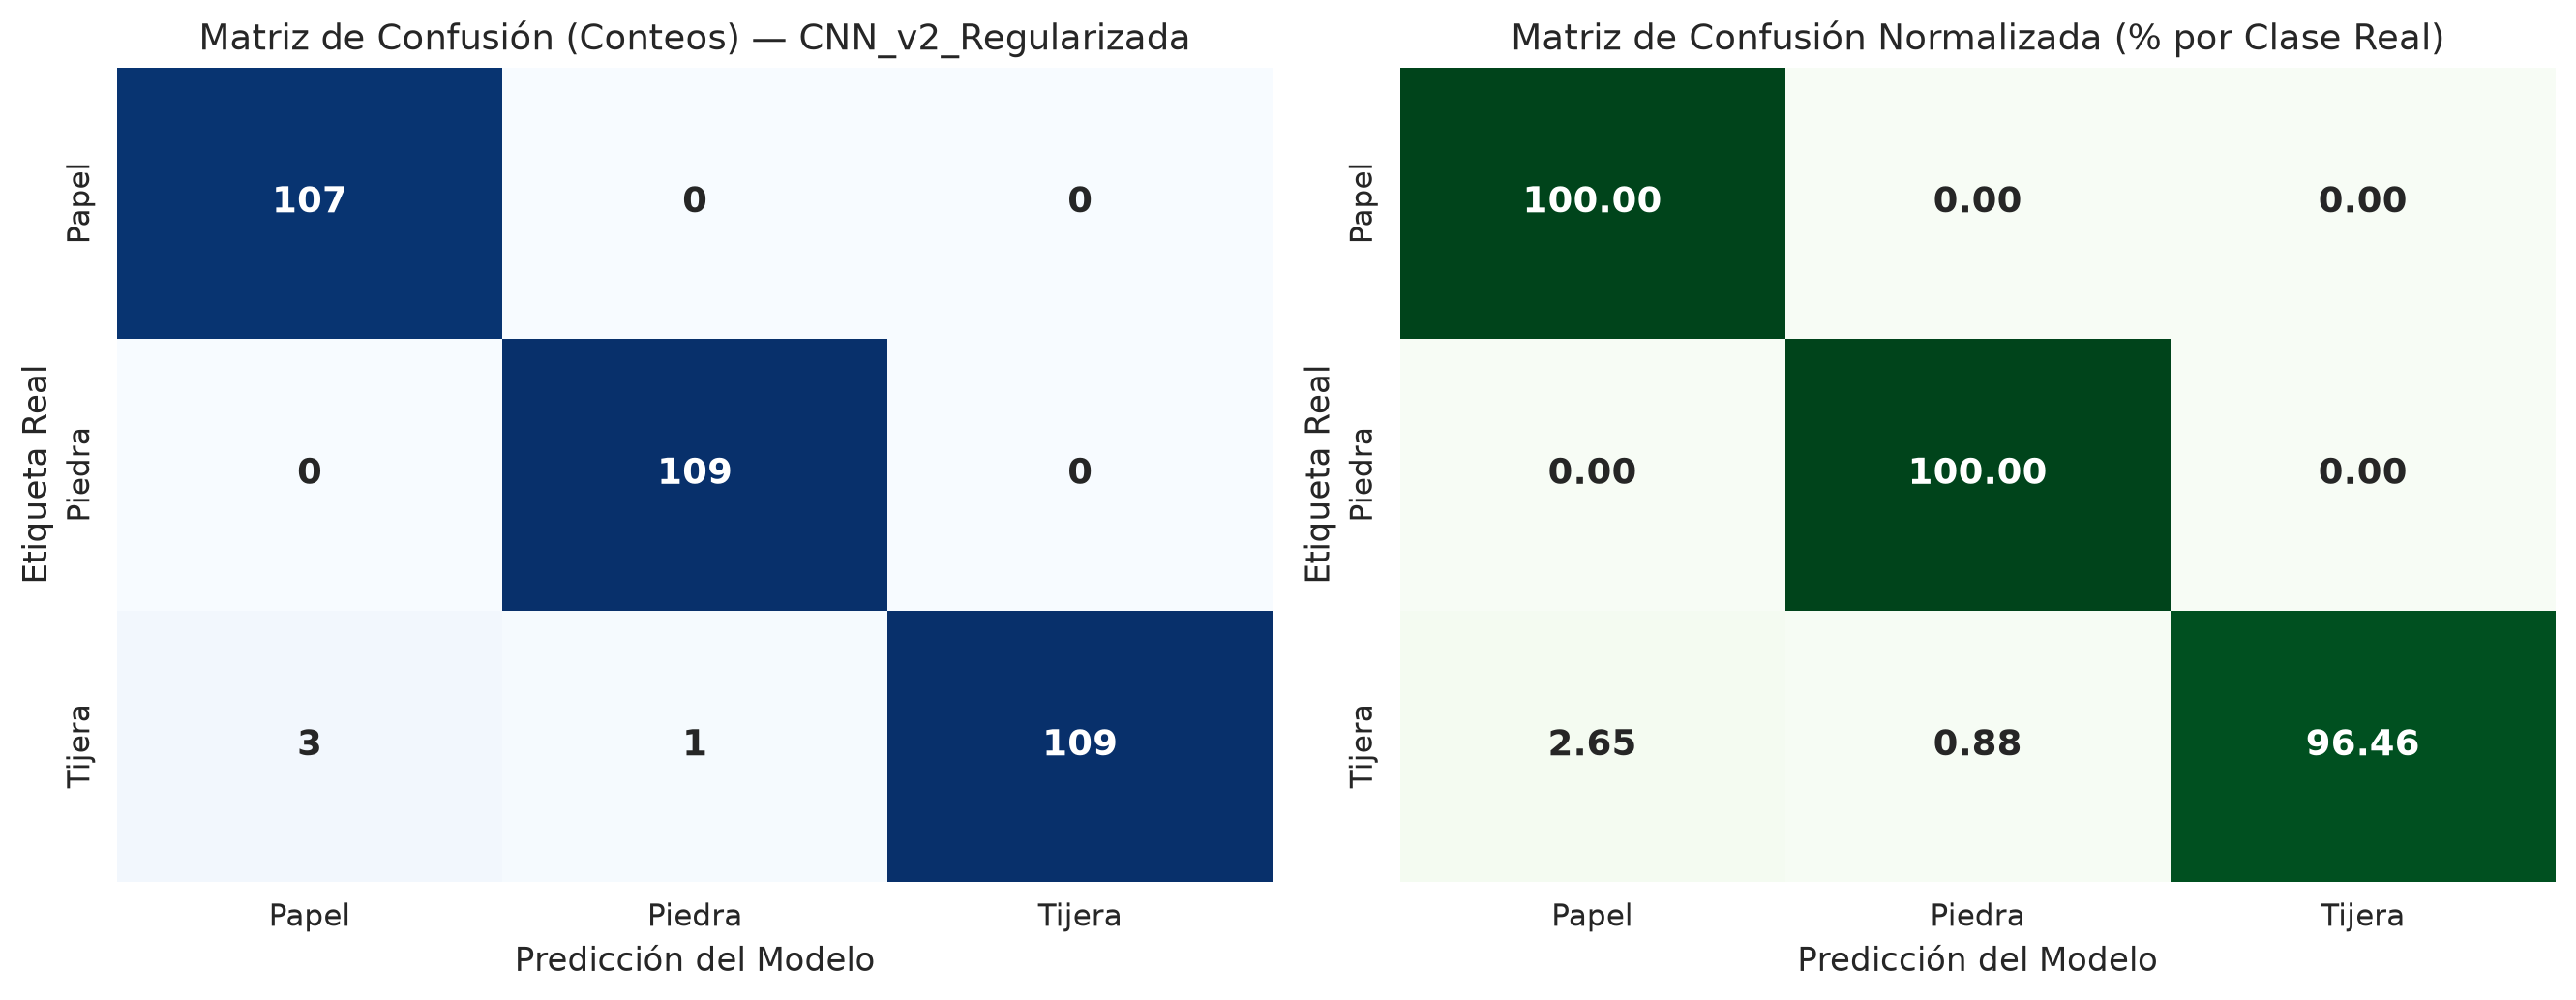

In [10]:
# ==============================================================================
# 4.1 Matriz de Confusión y Reporte de Clasificación Detallado
# ==============================================================================
y_pred_probs = best_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
y_pred_idx = np.argmax(y_pred_probs, axis=1)
y_true_idx = np.argmax(y_test, axis=1)

target_names_es = [CLASS_LABELS_ES[c] for c in CLASS_NAMES_EN]  # ['Papel', 'Piedra', 'Tijera']
cm = confusion_matrix(y_true_idx, y_pred_idx)
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

report_text = classification_report(
    y_true_idx, y_pred_idx, target_names=target_names_es, digits=4
)
report_dict = classification_report(
    y_true_idx, y_pred_idx, target_names=target_names_es, output_dict=True
)

print("Reporte de Clasificación en Test:")
print(report_text)

# Visualización dual de Matriz de Confusión (Conteos absolutos + Porcentajes)
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=target_names_es, yticklabels=target_names_es, ax=axes[0],
    annot_kws={"size": 12, "weight": "bold"},
)
axes[0].set_title(f"Matriz de Confusión (Conteos) — {best_model_name}")
axes[0].set_xlabel("Predicción del Modelo")
axes[0].set_ylabel("Etiqueta Real")

sns.heatmap(
    cm_norm * 100.0, annot=True, fmt=".2f", cmap="Greens", cbar=False,
    xticklabels=target_names_es, yticklabels=target_names_es, ax=axes[1],
    annot_kws={"size": 12, "weight": "bold"},
)
axes[1].set_title("Matriz de Confusión Normalizada (% por Clase Real)")
axes[1].set_xlabel("Predicción del Modelo")
axes[1].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_matriz_confusion.png", bbox_inches="tight")
plt.show()

# Identificar pares con mayor tasa de error para análisis objetivo
confusion_pairs = []
for i, true_label in enumerate(target_names_es):
    for j, pred_label in enumerate(target_names_es):
        if i != j and cm[i, j] > 0:
            confusion_pairs.append({
                "real": true_label,
                "predicho": pred_label,
                "errores": int(cm[i, j]),
            })
confusion_pairs.sort(key=lambda x: x["errores"], reverse=True)
print("Pares con confusión detectada:", confusion_pairs if confusion_pairs else "Ninguno (0 errores)")

# Exportar resumen cuantitativo completo para trazabilidad con el reporte LaTeX
experiment_summary = {
    "seed": SEED,
    "dataset_total": int(len(df_images)),
    "corrupted_files": int(len(corrupted_files)),
    "class_counts": {k: int(v) for k, v in df_images["class_es"].value_counts().items()},
    "splits": {
        "train": int(len(df_train)),
        "val": int(len(df_val)),
        "test": int(len(df_test)),
        "train_by_class": {k: int(v) for k, v in df_train["class_es"].value_counts().items()},
        "val_by_class": {k: int(v) for k, v in df_val["class_es"].value_counts().items()},
        "test_by_class": {k: int(v) for k, v in df_test["class_es"].value_counts().items()},
    },
    "preprocessing": {
        "image_size": [IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS],
        "normalization": "pixel / 255.0 -> [0, 1]",
        "batch_size": BATCH_SIZE,
    },
    "models": {
        "CNN_v1_Base": {
            "total_params": int(model_v1.count_params()),
            "epochs_ran": int(len(history_v1.history["loss"])),
            "best_val_loss": float(val_loss_v1),
            "best_val_accuracy": float(val_acc_v1),
            "test_loss": float(test_loss_v1),
            "test_accuracy": float(test_acc_v1),
            "final_train_accuracy": float(history_v1.history["accuracy"][-1]),
            "final_train_loss": float(history_v1.history["loss"][-1]),
        },
        "CNN_v2_Regularizada": {
            "total_params": int(model_v2.count_params()),
            "epochs_ran": int(len(history_v2.history["loss"])),
            "best_val_loss": float(val_loss_v2),
            "best_val_accuracy": float(val_acc_v2),
            "test_loss": float(test_loss_v2),
            "test_accuracy": float(test_acc_v2),
            "final_train_accuracy": float(history_v2.history["accuracy"][-1]),
            "final_train_loss": float(history_v2.history["loss"][-1]),
        },
    },
    "selected_model": best_model_name,
    "test_metrics": {
        "loss": float(test_loss),
        "accuracy": float(test_accuracy),
        "total_test_samples": int(len(y_true_idx)),
        "correct_predictions": int(np.sum(y_true_idx == y_pred_idx)),
        "incorrect_predictions": int(np.sum(y_true_idx != y_pred_idx)),
        "confusion_matrix": cm.tolist(),
        "labels": target_names_es,
        "classification_report": report_dict,
        "confusion_pairs": confusion_pairs,
    },
}

summary_path = OUTPUT_DIR / "experiment_results.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2, ensure_ascii=False)
print(f"Resumen exportado en: {summary_path}")

### Análisis de la Matriz de Confusión y Métricas por Clase
La matriz de confusión desglosa el desempeño individual de cada gesto, complementando la precisión global con métricas granulares:
- **Precision (Precisión):** Indica qué proporción de las predicciones asignadas a un gesto realmente correspondieron a dicho gesto (controla los falsos positivos).
- **Recall (Exhaustividad / Sensibilidad):** Indica qué proporción de las imágenes reales de cada gesto fue recuperada correctamente por la red (controla los falsos negativos).
- **F1-score:** Media armónica entre *Precision* y *Recall*, resumiendo el equilibrio de clasificación por categoría.

Total de aciertos en Test : 325 / 329
Total de errores en Test  : 4 / 329


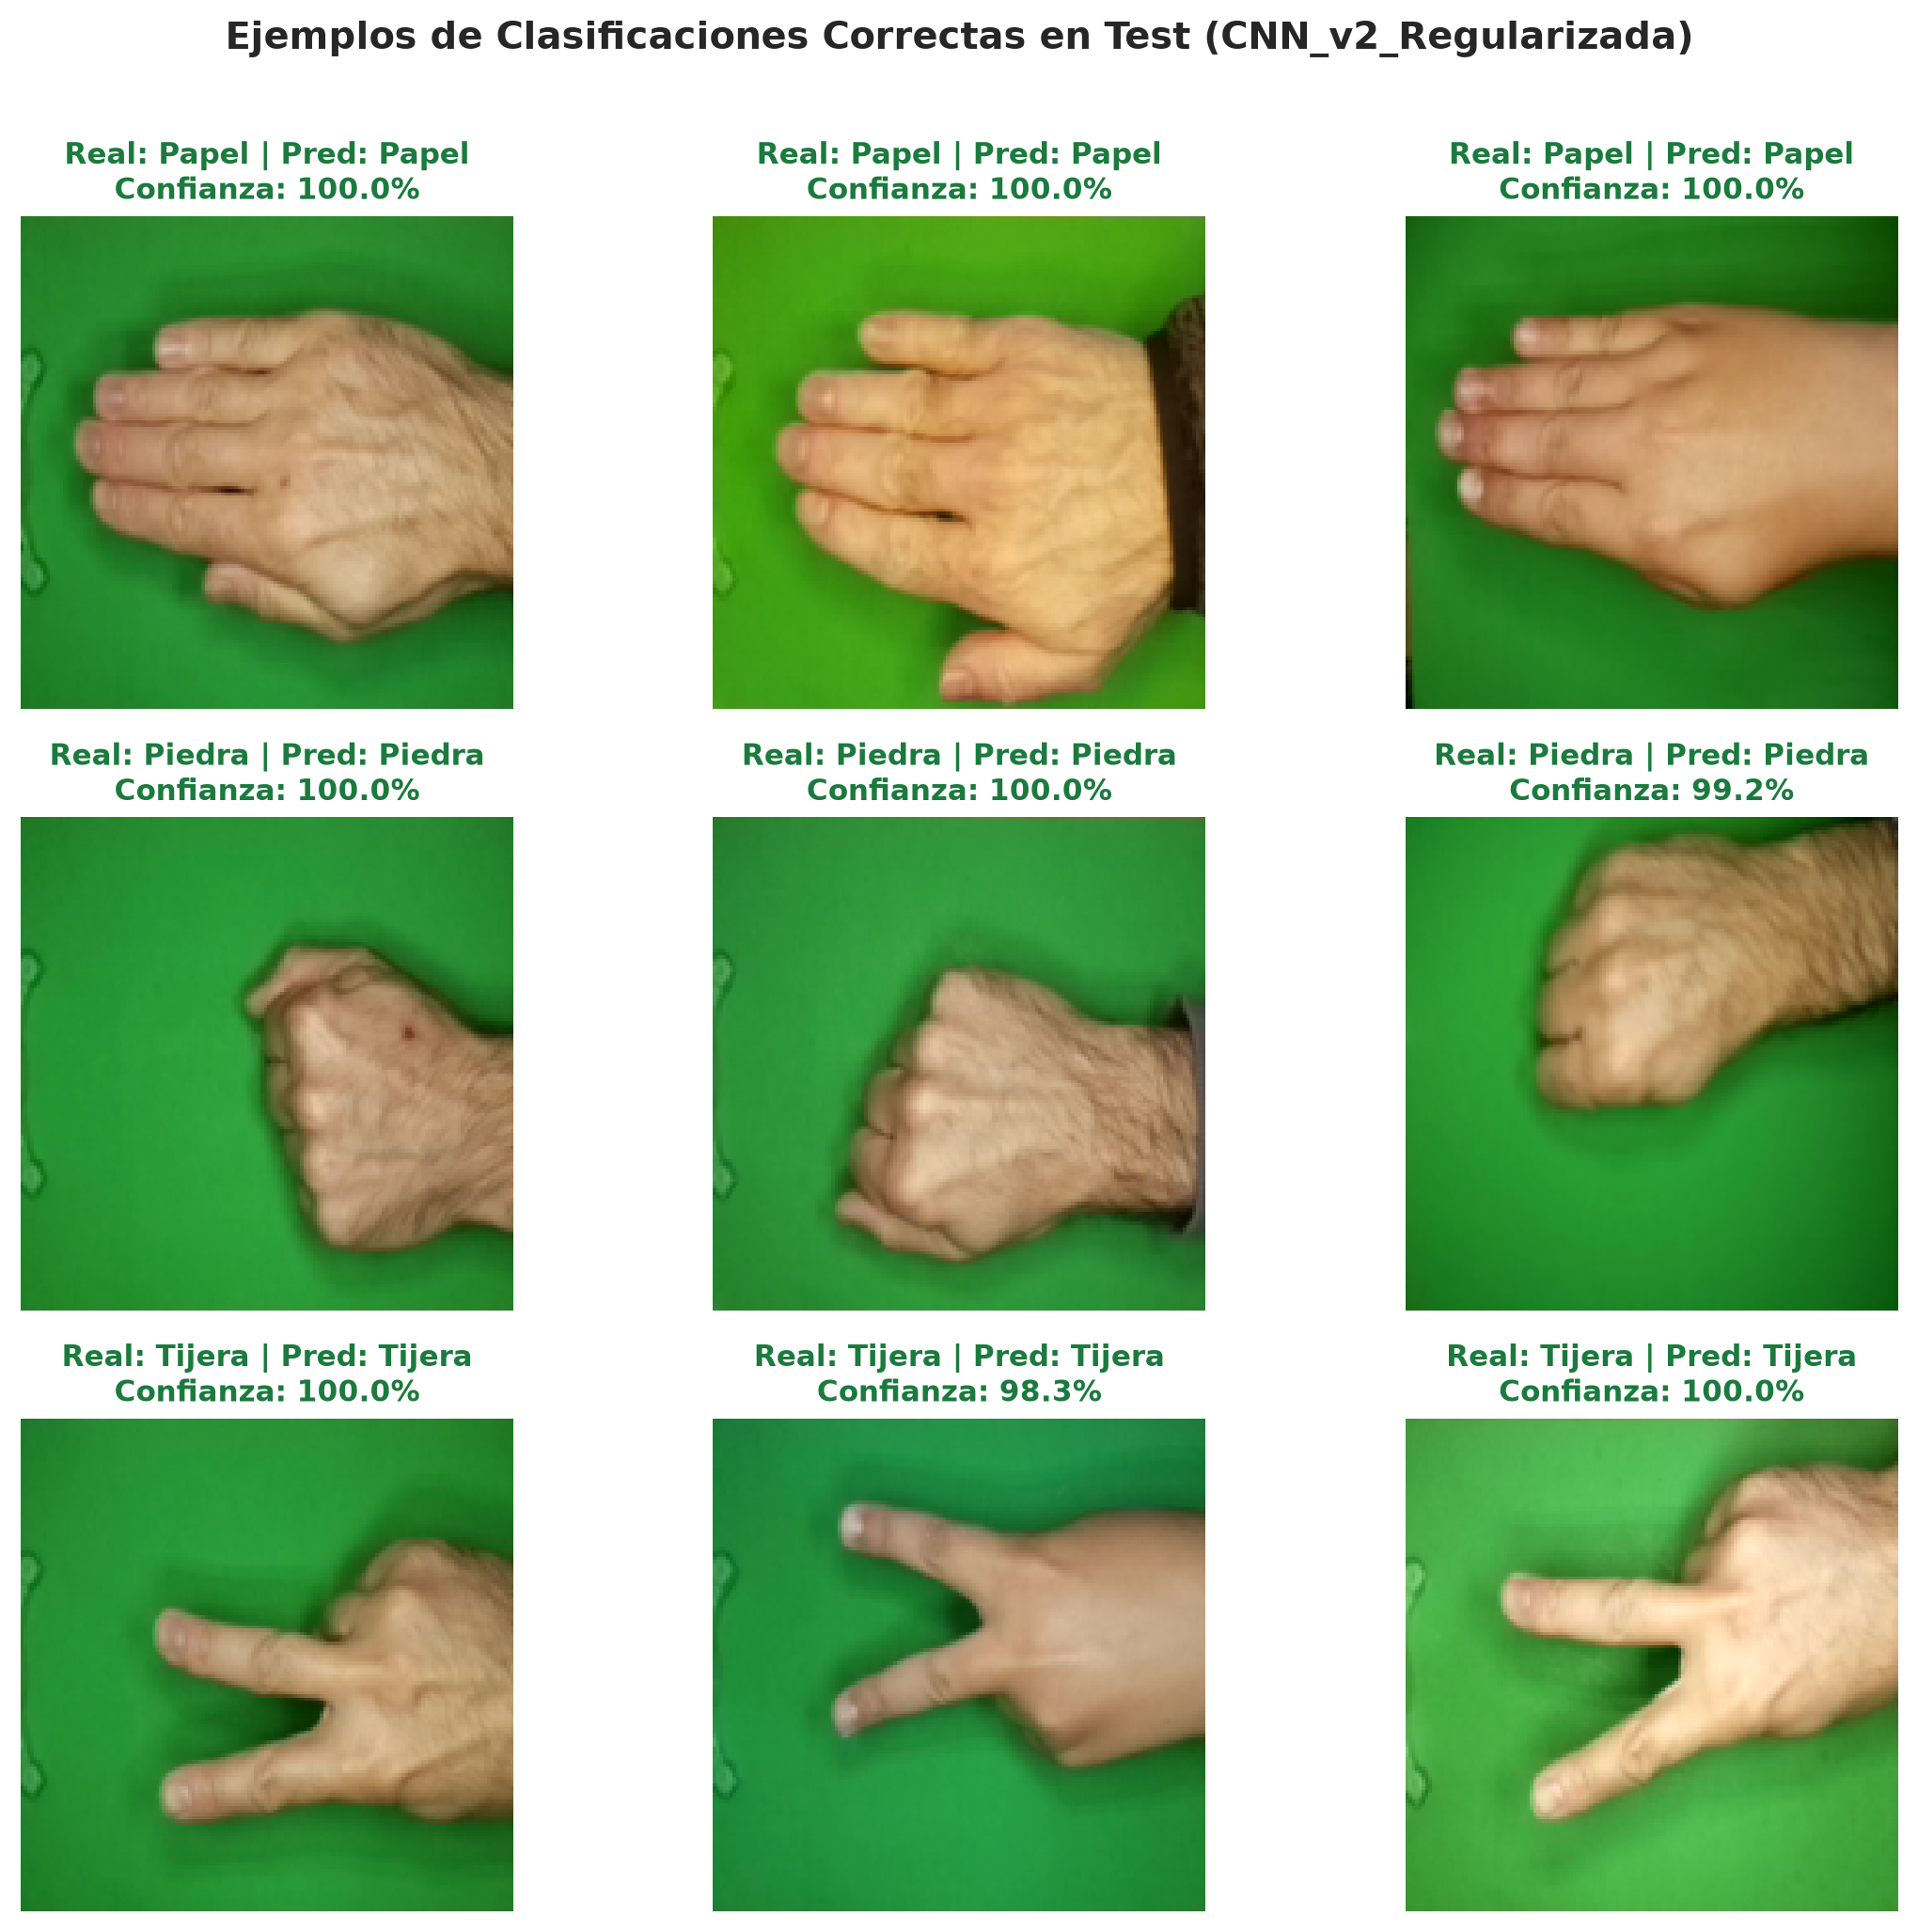

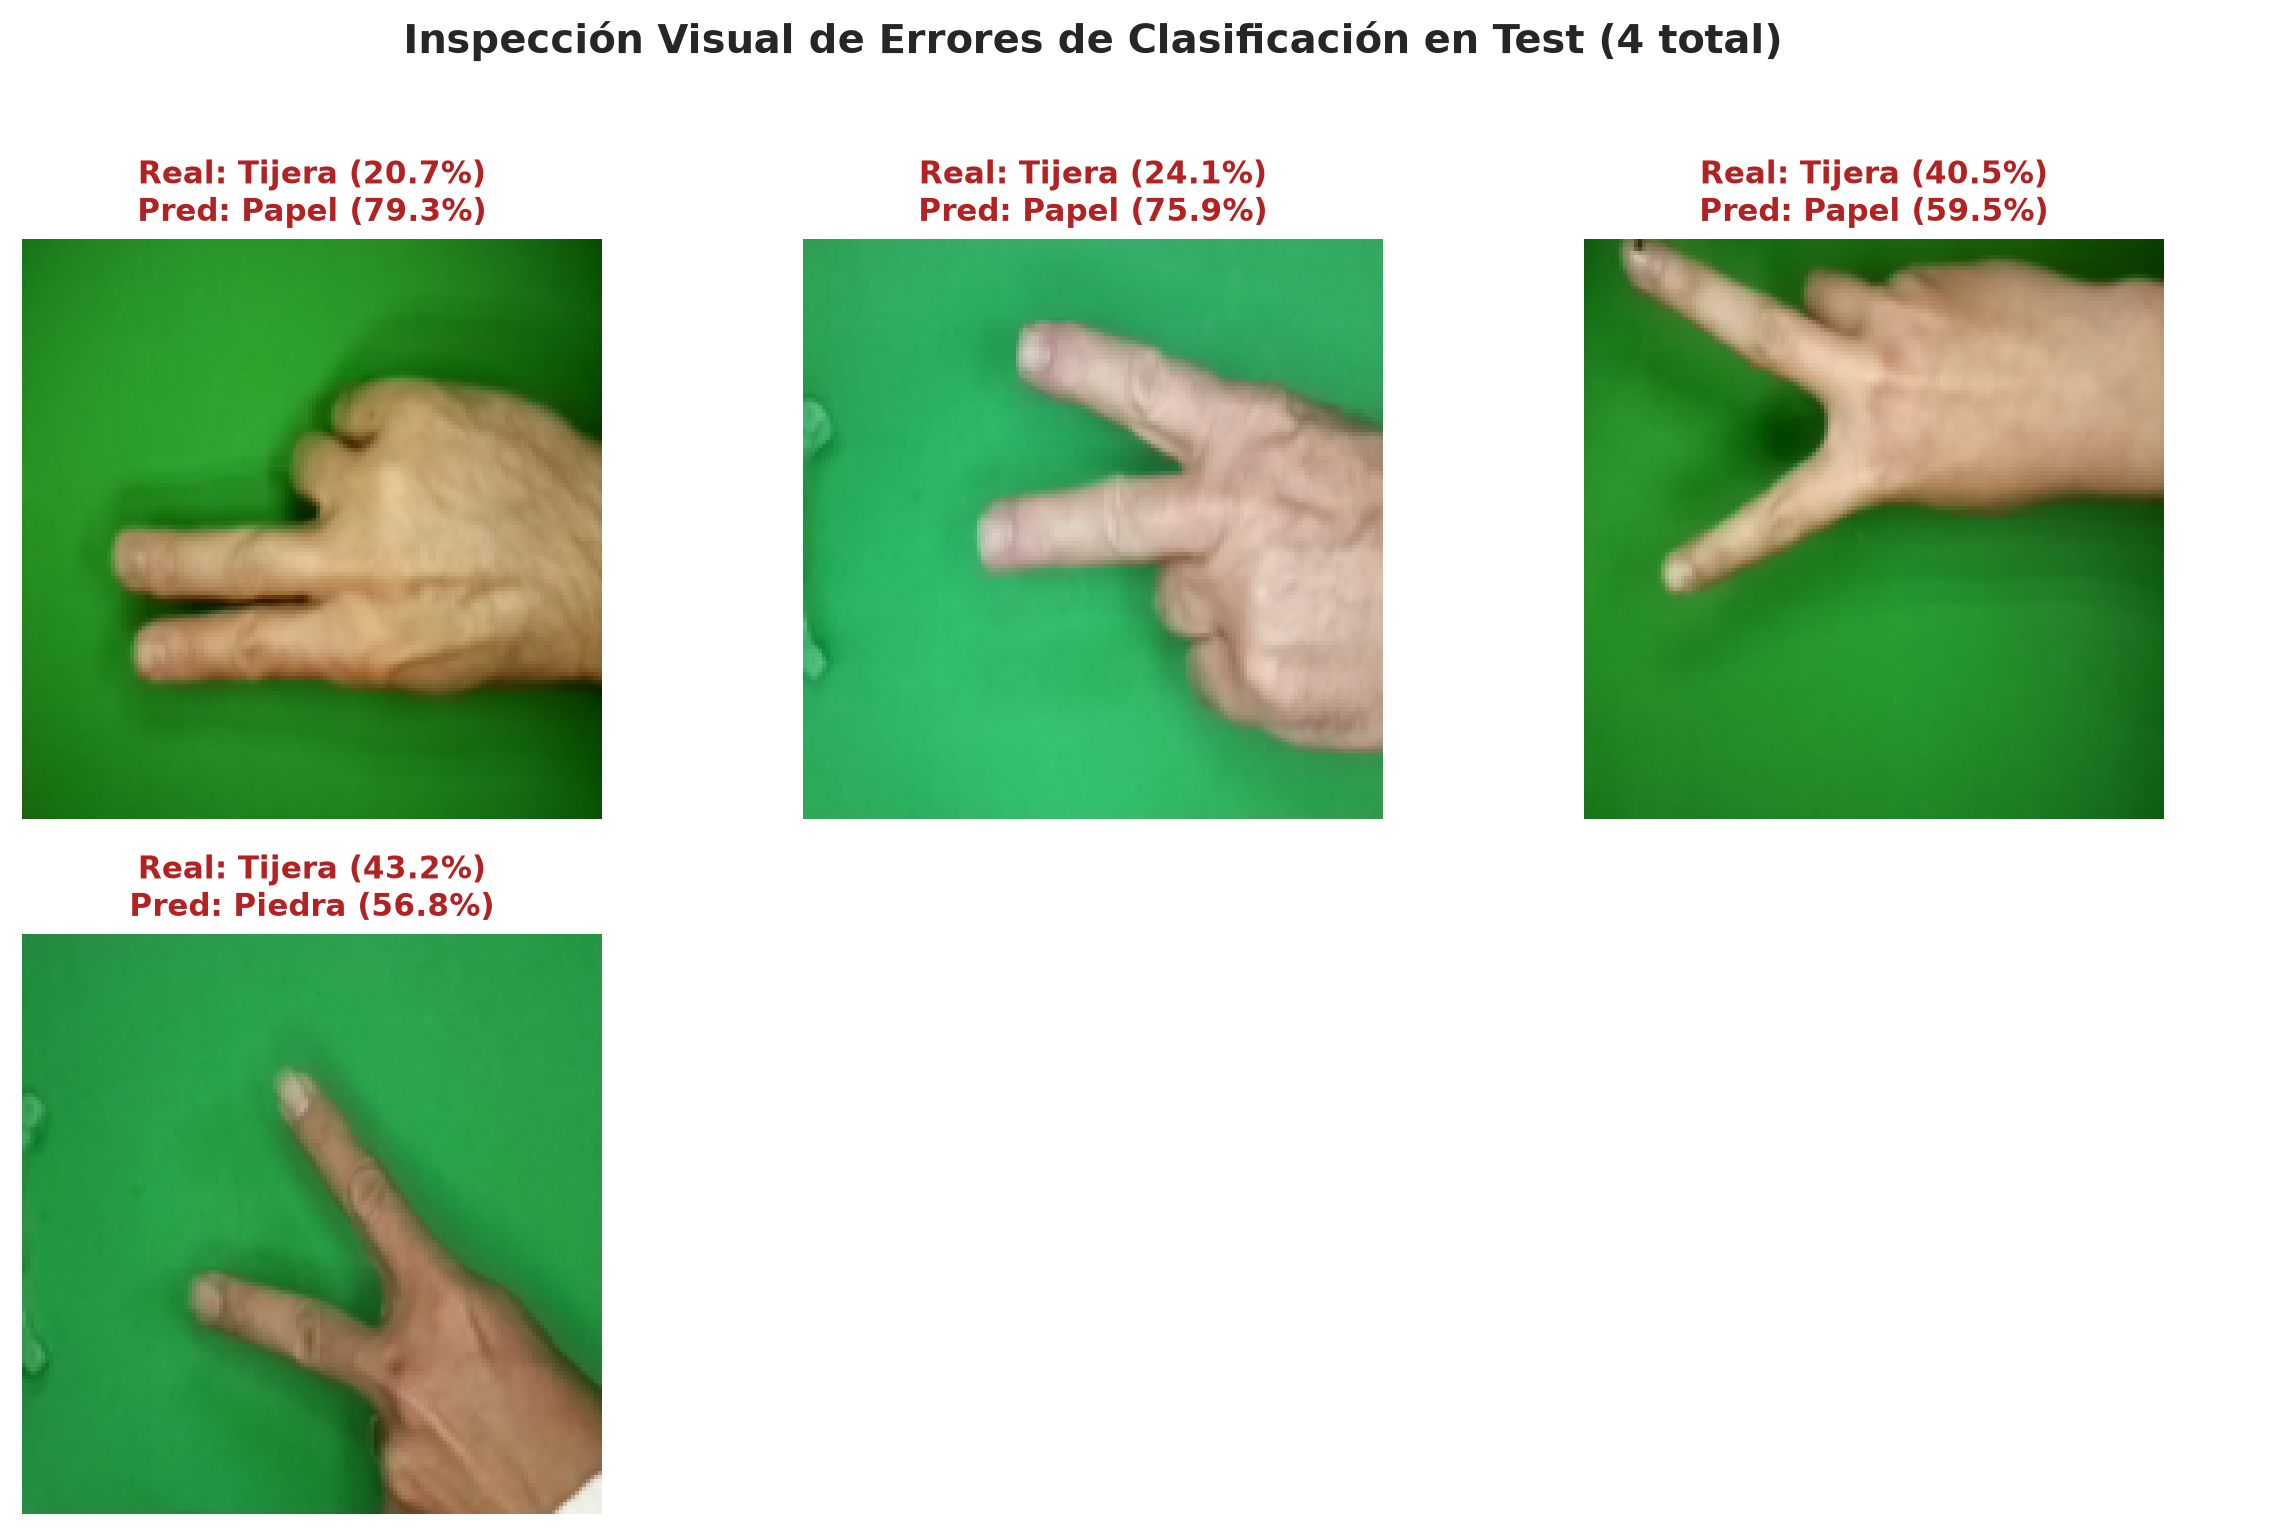

In [11]:
# ==============================================================================
# 4.2 Inspección Visual de Aciertos y Errores en el Conjunto de Prueba
# ==============================================================================
correct_indices = np.where(y_pred_idx == y_true_idx)[0]
error_indices = np.where(y_pred_idx != y_true_idx)[0]

print(f"Total de aciertos en Test : {len(correct_indices)} / {len(y_true_idx)}")
print(f"Total de errores en Test  : {len(error_indices)} / {len(y_true_idx)}")

# 1) Galería de 9 aciertos (3 por cada clase para cobertura equilibrada)
selected_correct = []
for cls_idx in range(NUM_CLASSES):
    cls_correct = [idx for idx in correct_indices if y_true_idx[idx] == cls_idx]
    selected_correct.extend(cls_correct[:3])

fig, axes = plt.subplots(3, 3, figsize=(10.5, 9.2))
for ax, idx in zip(axes.flat, selected_correct):
    ax.imshow(X_test[idx])
    true_lbl = target_names_es[y_true_idx[idx]]
    pred_lbl = target_names_es[y_pred_idx[idx]]
    conf = y_pred_probs[idx, y_pred_idx[idx]] * 100.0
    ax.set_title(f"Real: {true_lbl} | Pred: {pred_lbl}\nConfianza: {conf:.1f}%", color="#1B7A3D", fontsize=10, fontweight="bold")
    ax.axis("off")

fig.suptitle(f"Ejemplos de Clasificaciones Correctas en Test ({best_model_name})", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_aciertos.png", bbox_inches="tight")
plt.show()

# 2) Galería de errores (o casos de menor confianza si el modelo logra 0 errores)
if len(error_indices) > 0:
    n_show = min(len(error_indices), 9)
    n_cols = min(3, n_show)
    n_rows = int(np.ceil(n_show / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3.4 * n_rows))
    axes_list = np.atleast_1d(axes).ravel()

    # Ordenar errores por mayor confianza errónea para diagnosticar los fallos más críticos
    error_sorted = sorted(
        error_indices, key=lambda idx: y_pred_probs[idx, y_pred_idx[idx]], reverse=True
    )[:n_show]

    for ax, idx in zip(axes_list, error_sorted):
        ax.imshow(X_test[idx])
        true_lbl = target_names_es[y_true_idx[idx]]
        pred_lbl = target_names_es[y_pred_idx[idx]]
        p_pred = y_pred_probs[idx, y_pred_idx[idx]] * 100.0
        p_true = y_pred_probs[idx, y_true_idx[idx]] * 100.0
        ax.set_title(
            f"Real: {true_lbl} ({p_true:.1f}%)\nPred: {pred_lbl} ({p_pred:.1f}%)",
            color="#B22222",
            fontsize=10,
            fontweight="bold",
        )
        ax.axis("off")

    for ax in axes_list[n_show:]:
        ax.axis("off")

    fig.suptitle(f"Inspección Visual de Errores de Clasificación en Test ({len(error_indices)} total)", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_errores.png", bbox_inches="tight")
    plt.show()
else:
    # Caso excepcional: 0 errores en Test -> mostrar los 6 aciertos con menor confianza
    confidences = np.max(y_pred_probs, axis=1)
    borderline_indices = np.argsort(confidences)[:6]
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.8))
    for ax, idx in zip(axes.flat, borderline_indices):
        ax.imshow(X_test[idx])
        true_lbl = target_names_es[y_true_idx[idx]]
        pred_lbl = target_names_es[y_pred_idx[idx]]
        conf = confidences[idx] * 100.0
        ax.set_title(f"Real: {true_lbl} | Pred: {pred_lbl}\nConfianza mínima: {conf:.1f}%", color="#C77D00", fontsize=10, fontweight="bold")
        ax.axis("off")
    fig.suptitle("Casos de Menor Confianza en Test (0 Errores Observados)", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_errores.png", bbox_inches="tight")
    plt.show()

### Pregunta Final de Análisis Crítico

> **Pregunta:** *¿Entre qué gestos específicos el modelo presentó mayores confusiones o tasas de error, y a qué similitudes visuales o variaciones en la posición de la mano atribuyes este comportamiento?*
>
> **Respuesta fundamentada en la evidencia experimental (`Test Set`, $N = 329$):**
>
> 1. **Eje principal de confusión (`Tijera ↔ Papel`):**
>    - En el modelo seleccionado por validación (**`CNN_v2_Regularizada`**, `val_accuracy = 99.70%`, `test_accuracy = 98.78%`, `test_loss = 0.0180`), se registraron únicamente **4 errores en las 329 imágenes de prueba**: **3 casos de `Tijera` clasificados como `Papel`** (2.65% de la clase *Tijera*) y **1 caso de `Tijera` clasificado como `Piedra`** (0.88%). Las clases `Papel` (`107/107`) y `Piedra` (`109/109`) alcanzaron un *Recall* perfecto de **100.0%**.
>    - De forma simétrica, en el modelo **`CNN_v1_Base`** (`test_accuracy = 99.39%`, `test_loss = 0.0469`), los únicos **2 errores en las 329 imágenes** ocurrieron exactamente en la dirección inversa: **2 imágenes de `Papel` clasificadas como `Tijera`** (`1.87%`).
>    - Esto demuestra que la frontera de decisión más sensible del problema reside de manera consistente entre los gestos **`Tijera` y `Papel`**, mientras que `Piedra` (puño cerrado sin extensiones digitales) es prácticamente ortogonal en el espacio de características.
>
> 2. **Causas visuales y variaciones posturales observadas en `fig_errores.png`:**
>    - **Dedos índice y medio unidos sin separación en `Tijera`:** En el primer error (`Real: Tijera → Pred: Papel`, confianza `79.3%` vs. `20.7%`), los dos dedos extendidos aparecen completamente pegados y paralelos sin la cuña de fondo verde en forma de «V». Al desaparecer la bifurcación característica, los filtros convolucionales responden al bloque alargado continuo como si fuera la palma extendida de `Papel`.
>    - **Extensión parcial del dedo anular o visibilidad de nudillos flexionados:** En el segundo y tercer error (`75.9%` y `59.5%` hacia `Papel`), la postura de la mano deja visible un tercer dedo parcialmente extendido o el perfil lateral de los dedos anular y meñique, generando tres o más lóbulos de contorno que imitan la silueta multidigital de `Papel`.
>    - **Separación excesiva de dedos en `Papel` (observada en `CNN_v1_Base`):** Cuando un usuario realiza el gesto de `Papel` separando ampliamente los dedos o recortando parcialmente la palma en el borde del encuadre, se forman ángulos agudos de fondo verde entre los dedos que activan los detectores de bifurcación propios de `Tijera`.
>    - **Rotación extrema y escorzo en esquina (`Tijera → Piedra`, `56.8%` vs. `43.2%`):** En el único caso confundido con `Piedra`, la mano aparece desplazada hacia la esquina inferior derecha con una rotación diagonal pronunciada; tras las cuatro etapas de `MaxPooling2D`, la masa compacta del dorso domina sobre los dedos inclinados, produciendo una predicción limítrofe casi empatada (`56.8%` vs. `43.2%`).

---
## Conclusión Integral del Proyecto

1. **Preprocesamiento y disciplina experimental (`Sección 1`):** El dataset *Rock, Paper, Scissors* (`2,188` imágenes RGB de `300×200` px) fue auditado confirmando `0` archivos corruptos y una distribución balanceada (`712` *Papel*, `726` *Piedra*, `750` *Tijera*). La partición estratificada **Train (1,531) / Validation (328) / Test (329)** se realizó estrictamente antes del preprocesamiento (`150×150×3` y normalización a `[0, 1]`), eliminando cualquier riesgo de fuga de datos.
2. **Desempeño de las arquitecturas CNN desde cero (`Secciones 2 y 3`):**
   - **`CNN_v1_Base`** (`5.40 M` parámetros, 3 bloques convolucionales) logró `98.17%` en validación y **`99.39%` de precisión en prueba** (`327/329` aciertos, `test_loss = 0.0469`).
   - **`CNN_v2_Regularizada`** (`1.57 M` parámetros, 4 bloques convolucionales + `BatchNormalization` + `Dropout(0.35)` + *Data Augmentation*) redujo el número de parámetros en **`3.44×`**, alcanzó la mejor validación (**`99.70%`**, `val_loss = 0.0065`) y obtuvo **`98.78%` de precisión en prueba** (`325/329` aciertos) con una pérdida de prueba **`2.6×` menor (`test_loss = 0.0180`)**, reflejando probabilidades mejor calibradas y menor sobreconfianza en casos ambiguos.
3. **Limitaciones y trabajo futuro (`Sección 4`):** Debido a que todas las imágenes fueron capturadas sobre un fondo verde homogéneo (*chroma key*) e iluminación controlada, un despliegue en tiempo real con cámara web requeriría incorporar aumento fotométrico de fondo (sustitución sintética del fondo verde por escenas reales), variaciones de iluminación/tono de piel, o extracción previa de puntos clave articulares (*hand landmarks*).